**Process (Roughly):**
1. Get the images
2. Extract keypoints
3. Generate keypoint dataset
4. Split & store it
5. Use dataset to train the model
6. Store the model
7. Use the model on gestures

# Imports

In [ ]:
!pip install -q mediapipe mlflow # ==0.10.7

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 2.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.5/41.5 MB 15.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 44.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 37.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 34.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.7/137.7 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 270.4/270.4 kB 10.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 14.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13

In [ ]:
import os
import numpy as np
import pandas as pd
from pathlib import Path

from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import json
import time

from typing import Optional,Literal

In [ ]:
import mediapipe as mp
from mediapipe.tasks.python import vision
from mediapipe.tasks.python.core.base_options import BaseOptions
import cv2

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
import torchvision.transforms as T

In [ ]:
import os
from google.colab import drive, files

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import shutil
import zipfile
from google.colab import files

def zip_folder(folder_path, zip_name=None):
    """Zip a folder and download the resulting archive."""
    folder_path = os.path.abspath(folder_path)

    if zip_name is None:
        zip_name = os.path.basename(folder_path.rstrip("/"))

    zip_path = shutil.make_archive(zip_name, "zip", root_dir=os.path.dirname(folder_path), base_dir=os.path.basename(folder_path))

    files.download(zip_path)
    return zip_path

def unzip_folder(zip_path, output_dir="/content"):
    """Extract a Zip archive."""
    os.makedirs(output_dir, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(output_dir)
    return output_dir

In [ ]:
import kagglehub

# Load dataset
DATASET_DIR = "/root/.cache/kagglehub/datasets/joebeachcapital/chicagofswild/versions/2"
if not os.path.exists(DATASET_DIR):
  DATASET_DIR = kagglehub.dataset_download("joebeachcapital/chicagofswild")

print("Data directory: ", DATASET_DIR)

In [ ]:
# Data directories ---
VIDEO_DIR = os.path.join(DATASET_DIR, 'videos')
BBOX_DIR = os.path.join(DATASET_DIR, 'BBox')
META_CSV = os.path.join(DATASET_DIR, 'ChicagoFSWild.csv')
HAND_ANNOT_CSV = os.path.join(DATASET_DIR, 'HandAnnotation.csv')
RESULT_DIR = '/content/drive/MyDrive/Навчання/Diploma/Saved_Experiments' # where saves will go

In [ ]:
if not os.path.exists(VIDEO_DIR):
  print("No videos extracted - archive needs to be processed.")

In [ ]:
os.makedirs(VIDEO_DIR)
!tar -xvf  /root/.cache/kagglehub/datasets/joebeachcapital/chicagofswild/versions/2/ChicagoFSWild-Frames.tgz -C /root/.cache/kagglehub/datasets/joebeachcapital/chicagofswild/versions/2/videos

Streaming output truncated to the last 5000 lines.
youtube_6/tom_humphries_6587/0022.jpg
youtube_6/tom_humphries_6587/0023.jpg
youtube_6/tom_humphries_6587/0020.jpg
youtube_6/tom_humphries_6587/0017.jpg
youtube_6/tom_humphries_6587/0075.jpg
youtube_6/tom_humphries_6587/0060.jpg
youtube_6/tom_humphries_6587/0073.jpg
youtube_6/tom_humphries_6587/0014.jpg
youtube_6/tom_humphries_6587/0070.jpg
youtube_6/tom_humphries_6587/0044.jpg
youtube_6/tom_humphries_6587/0057.jpg
youtube_6/tom_humphries_6587/0009.jpg
youtube_6/tom_humphries_6587/0063.jpg
youtube_6/tom_humphries_6587/0068.jpg
youtube_6/tom_humphries_6587/0088.jpg
youtube_6/tom_humphries_6587/0091.jpg
youtube_6/tom_humphries_6587/0080.jpg
youtube_6/tom_humphries_6587/0038.jpg
youtube_6/peter_hauser_6928/
youtube_6/peter_hauser_6928/0035.jpg
youtube_6/peter_hauser_6928/0036.jpg
youtube_6/peter_hauser_6928/0003.jpg
youtube_6/peter_hauser_6928/0058.jpg
youtube_6/peter_hauser_6928/0018.jpg
youtube_6/peter_hauser_6928/0024.jpg
youtube_6/pete

In [ ]:
LANDMARK_NPZ = 'ChicagoFSWild_landmarks_both.npz'
#FRAME_DATA = '/content/WLASL_FRAMES/'
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BATCH_SIZE = 8
BLANK_SYMBOL_IDX = 0
MAX_FRAMES = 32 # For CNN limits, currently ignored by GestureDataset as whole video is being used
NUM_LANDMARKS = 42

In [ ]:
DEVICE

device(type='cpu')

# Data Pre-processing

## Extracting Metadata

Json data organizing - separate each video metadata from the instances, so each video has:

[gloss, video_path, split, fps, frame start, frame end]

Json -> loaded dataframe -> separate instances -> clean dataframe

In [ ]:
metadata_df = pd.read_csv(META_CSV, sep=',')
print("Total instances: ", metadata_df.shape)
metadata_df.head()

Total instances:  (7304, 12)


,Unnamed: 0,filename,url,start_time,number_of_frames,width,height,label_proc,label_raw,label_notes,partition,signer
0,0,aslized/elsie_stecker_0001,https://www.youtube.com/watch?v=4YIYRu2PERg,0:00:17.740000,19,640,360,dc,dc,dc?,train,0
1,1,aslized/elsie_stecker_0002,https://www.youtube.com/watch?v=4YIYRu2PERg,0:00:29.250000,13,640,360,ed,ed,NaN,train,0
2,2,aslized/elsie_stecker_0003,https://www.youtube.com/watch?v=4YIYRu2PERg,0:00:55.080000,42,640,360,aslized,aslized,NaN,train,0
3,3,aslized/elsie_stecker_0004,https://www.youtube.com/watch?v=4YIYRu2PERg,0:00:57.440000,66,640,360,asl literature,asl!literature,NaN,train,0
4,4,aslized/elsie_stecker_0005,https://www.youtube.com/watch?v=4YIYRu2PERg,0:01:10.275000,32,640,360,alized,alized,NaN,train,0


In [ ]:
metadata_df.describe()

,Unnamed: 0,number_of_frames,width,height,signer
count,7304.000000,7304.000000,7304.000000,7304.000000,7304.000000
mean,3651.500000,28.085843,738.927163,431.233297,63.193593
std,2108.627516,21.460386,292.717128,157.128667,41.109334
min,0.000000,2.000000,320.000000,240.000000,0.000000
25%,1825.750000,14.000000,640.000000,360.000000,31.000000
50%,3651.500000,22.000000,640.000000,360.000000,50.000000
75%,5477.250000,35.000000,640.000000,480.000000,87.000000
max,7303.000000,296.000000,1920.000000,1080.000000,159.000000


In [ ]:
metadata_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7304 entries, 0 to 7303
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Unnamed: 0        7304 non-null   int64 
 1   filename          7304 non-null   object
 2   url               7304 non-null   object
 3   start_time        7304 non-null   object
 4   number_of_frames  7304 non-null   int64 
 5   width             7304 non-null   int64 
 6   height            7304 non-null   int64 
 7   label_proc        7304 non-null   object
 8   label_raw         7304 non-null   object
 9   label_notes       902 non-null    object
 10  partition         7304 non-null   object
 11  signer            7304 non-null   int64 
dtypes: int64(5), object(7)
memory usage: 684.9+ KB


In [ ]:
print(f"Partition quantities:\n{metadata_df['partition'].value_counts()}")

Partition quantities:
partition
train    5455
dev       981
test      868
Name: count, dtype: int64


Cleanup metadata - find video_id, frames_path, split, label, label_length.

In [ ]:
def min_frames_required(label: str) -> int:
    """
    CTC needs at least one blank between two consecutive identical symbols (e.g. R R).
    Returns the minimum number of input timesteps needed to represent `label`.
    """
    if len(label) == 0:
        return 0
    extra_for_repeats = sum(1 for a, b in zip(label, label[1:]) if a == b)
    return len(label) + extra_for_repeats

In [ ]:
def prepare_meta(
    meta_df: pd.DataFrame,
    frames_root: str,
    frames_subdir_template: str = "{filename}",
    partition_column: str = "partition",
    label_column: str = "label_proc",
    frame_count_column: str = "number_of_frames"
    ):
    """
    Loads .csv and builds the per-sequence metadata dataframe.
    Also filters out sequences where CTC is structurally wrong (min_frames_required).
    """
    meta_df = meta_df.rename(columns={"filename": "video_id"})
    meta_df["frames_path"] = meta_df["video_id"].apply(
        lambda f: str(Path(frames_root) / frames_subdir_template.format(filename=f))
    )
    meta_df["split"] = meta_df[partition_column]
    meta_df["label"] = meta_df[label_column].astype(str)

    # drop rows whose frame dir doesn't exist
    exists_mask = meta_df["frames_path"].apply(lambda p: Path(p).is_dir())
    if (~exists_mask).any():
        print(f"WARNING: dropping {(~exists_mask).sum()} rows with missing frame directories.")
    meta_df = meta_df[exists_mask].reset_index(drop=True)

    # drop rows that have off frame count for CTC
    required = meta_df["label"].apply(min_frames_required)
    feasible_mask = meta_df[frame_count_column] >= required
    if (~feasible_mask).any():
        print(f"WARNING: dropping {(~feasible_mask).sum()} rows where frame count is too short for CTC to represent the label.")
    meta_df = meta_df[feasible_mask].reset_index(drop=True)

    print(f"Prepared metadata: {len(meta_df)} usable sequences across splits {meta_df['split'].unique().tolist()}")
    return meta_df

In [ ]:
metadata_df_clean = prepare_meta(metadata_df, VIDEO_DIR)

Prepared metadata: 7302 usable sequences across splits ['train', 'dev', 'test']


In [ ]:
print(f"Partition quantities:\n{metadata_df_clean['partition'].value_counts()}")


Partition quantities:
partition
train    5455
dev       979
test      868
Name: count, dtype: int64


Encode the labels to a list of characters. For that, we make a CTC - connectionist temporal classification or something like that.

In [ ]:
def encode_label(label: str, vocab: dict) -> list:
    """Encodes a label string into a list of vocab indices. Unknown chars raise, not skip silently."""
    try:
        return [vocab[ch] for ch in label]
    except KeyError as e:
        raise ValueError(f"Character {e} in label '{label}' is not in the vocabulary.")


def decode_label(indices, vocab: dict) -> str:
    """Inverse of encode_label."""
    inv_vocab = {i: ch for ch, i in vocab.items()}
    return "".join(inv_vocab[i] for i in indices)

In [ ]:
def create_vocabulary(df: pd.DataFrame, label_column: str = "label_proc") -> dict:
    """
    Builds a char -> index vocabulary from the actual data rather than an alphabet.
    The dataset holds more than just A-Z, it may have ampersands, etc.
    Returns: {char: index}, where index 0 is reserved for CTC blank.
    """
    chars = set()
    for label in df[label_column].astype(str):
        chars.update(label)

    vocab = {ch: i + 1 for i, ch in enumerate(sorted(chars))}  # +1 leaves 0 free for blank
    print(f"Built vocabulary with {len(vocab)} symbols (+1 blank): {sorted(vocab.keys())}")
    return vocab

In [ ]:
char_vocab = create_vocabulary(metadata_df_clean)

Built vocabulary with 31 symbols (+1 blank): [' ', '&', "'", '.', '@', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']


To display of some of the dataset videos:

In [ ]:
from IPython.display import HTML, display
from base64 import b64encode

def display_video(video_path, width=600, is_file: bool = True):
  if is_file:
    video_file = open(video_path, "rb").read()
    video_url = f"data:video/mp4;base64,{b64encode(video_file).decode()}"
  else:
    video_url = video_path

  # Return HTML video player
  return HTML(f"""
  <video width="{width}" controls>
      <source src="{video_url}" type="video/mp4">
  </video>
  """)

display_video(str(metadata_df_clean['url'][0]), is_file = False)

Let's test the bounding boxes too, they may be useful later.

Video: /content/ChicagoFSWild_lite/videos/aslized/elsie_stecker_0001
Frames: 19
BBox files: 19


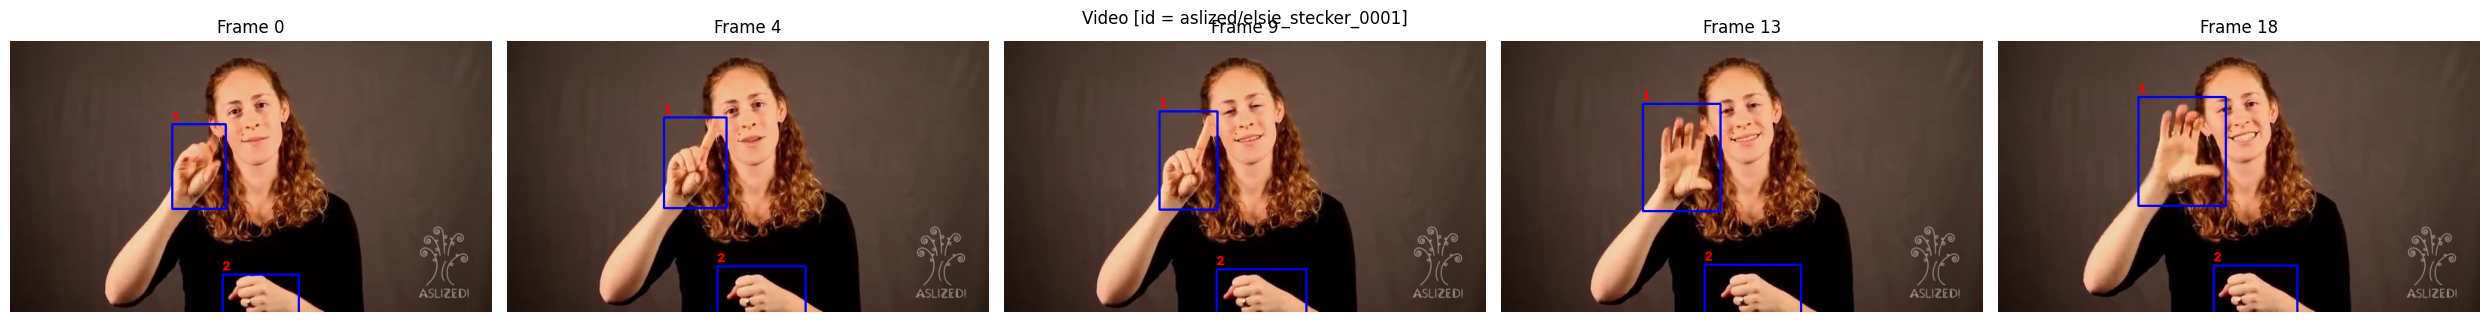

In [ ]:
def test_bbox_frames(video_meta_df: pd.DataFrame, num_frames: int = 5):
    video_meta = video_meta_df.iloc[0]

    video_dir = Path(VIDEO_DIR) / str(video_meta["video_id"])
    bbox_dir = Path(BBOX_DIR) / str(video_meta["video_id"])
    frame_width, frame_height = video_meta["width"], video_meta["height"]

    # video frames
    frame_files = sorted(
        [p for p in video_dir.iterdir() if p.is_file()],
        key=lambda p: p.name
    )

    # bbox txt files
    bbox_files = sorted(bbox_dir.glob("*.txt"),key=lambda p: p.name)

    total_frames = len(frame_files)

    if total_frames == 0:
        print(f"No frames found in {video_dir}")
        return

    print(f"Video: {video_dir}")
    print(f"Frames: {total_frames}")
    print(f"BBox files: {len(bbox_files)}")


    sampled_frames = np.linspace(0, total_frames - 1, min(num_frames, total_frames), dtype=int)
    fig, axes = plt.subplots(1, len(sampled_frames),figsize=(5 * len(sampled_frames), 5))
    if len(sampled_frames) == 1:
        axes = [axes]

    for i, frame_idx in enumerate(sampled_frames):
        frame_path = frame_files[frame_idx]
        frame = cv2.imread(str(frame_path))
        frame = cv2.resize(frame, (frame_width, frame_height))

        if frame is None:
          axes[i].text(0.5, 0.5, f"ERROR [Frame {frame_idx}]", ha='center', va='center')
        else:
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            if frame_idx < len(bbox_files):
                bbox_file = bbox_files[frame_idx]
                with open(bbox_file, "r") as f:
                    for line in f:
                        line = line.strip()
                        if not line:
                            continue
                        values = line.split(",")
                        if len(values) != 5:
                            continue
                        x1, y1, x2, y2, id = map(int, values)
                        cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 0, 255), 2)
                        cv2.putText(frame, str(id), (x1, max(y1 - 5, 0)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)
            # Display
            axes[i].imshow(frame)
            axes[i].set_title(f"Frame {frame_idx}")
        axes[i].axis('off')

    plt.suptitle(f"Video [id = {video_meta['video_id']}]", y=0.8)
    plt.tight_layout()
    plt.show()

# Random video test
test_bbox_frames(metadata_df_clean)

## Extracting Mediapipe landmarks

We need only the standard hand landmarks, which start with the wrist and end with the fingertips. There are 42 total in mediapipe's landmarks, [0-20] and [21-41] (21 total) for each hand.

Landmarks should have important information regarding the video processing, such as:
- video_id [int]
- frame_id [int]
- hand [string]
- landmark_id [int]
- x,y,z [float]
- confidence [float] - not necessary, for noisy detections

It's efficient to save raw landmark data, which should be converted into processed (compiled) data later. Actual landmark data may have the **hand flags, landmarks, and their coordinates**, so **[B, F, H, L, C]**:
- B - batch
- F - frame id
- H - hand flag (left, right presence = 1 or 0)
- L - landmark id
- C - coordinates

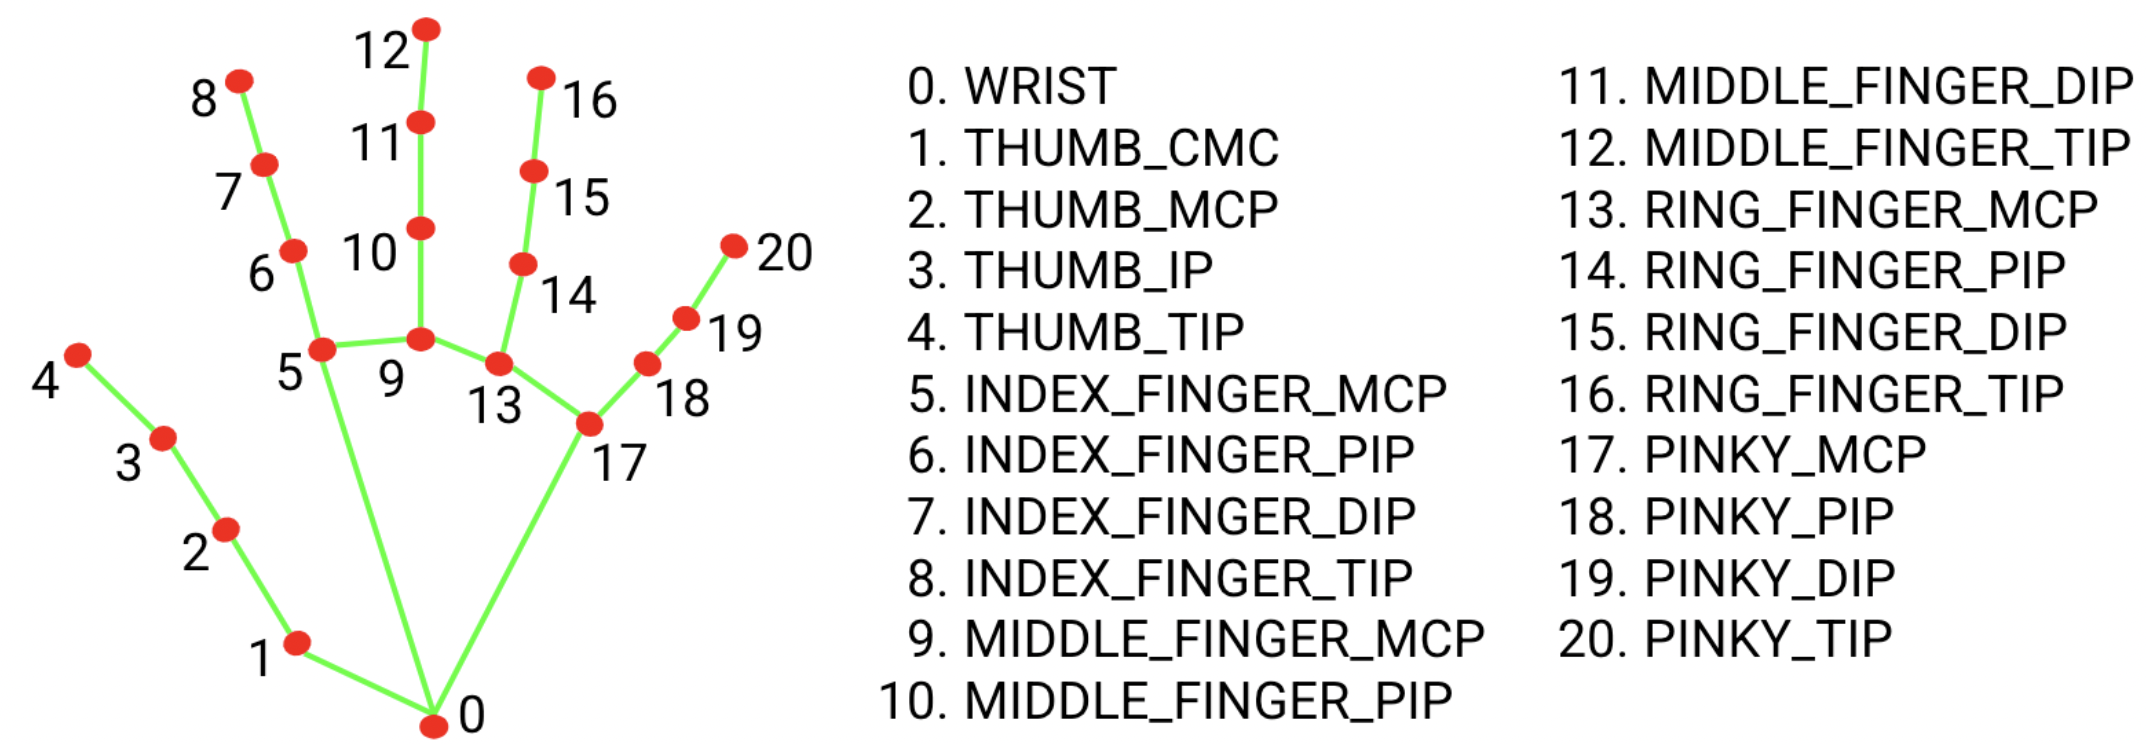

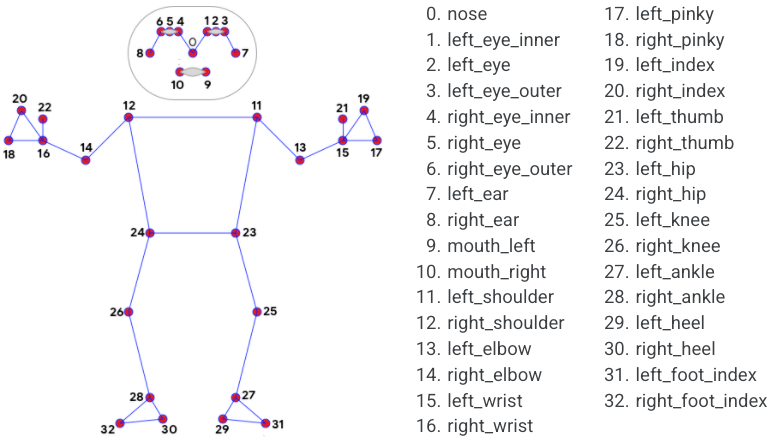

Needs a landmarker model from google apis.

https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/latest/hand_landmarker.task

In [ ]:
# THIS IS A LEGACY SOLUTION. NEW ONE IS THE LANDMARKER.
# mp_hands = mp.solutions.hands.Hands()
# mp_draw_utils = mp.solutions.drawing_utils

### Hands + Pose (final)

In [ ]:
class LandmarkConfig:
  """
  A config class for LandmarkExtractor. Holds values that are not typically changed during landmark detection process.
  """
  HAND_LANDMARKS = list(range(21)) # for both hands 0-21
  POSE_LANDMARKS = [11, 12, 13, 14, 15, 16] # shoulders and arms

  def __init__(self, lm_model_paths: dict, min_detection_confidence: float = 0.5, min_tracking_confidence: float = 0.5, default_detection_mode: Literal["video", "image"] = "video", num_hands: Literal[1, 2] = 2, use_pose: bool = True):
      """
      `lm_model_paths` format example: {"pose": "pose_landmarker.task", "hands": "hand_landmarker.task"}
      """
      if default_detection_mode not in ("video", "image"):
            raise ValueError(f"Detection mode must be either 'video' or 'image': {default_detection_mode}.")
      self.MIN_DETECTION_CONFIDENCE = min_detection_confidence
      self.MIN_TRACKING_CONFIDENCE = min_tracking_confidence # # if fails, detection occurs. better set to lower
      self.MODEL_PATHS = lm_model_paths
      self.default_detection_mode = default_detection_mode
      self.detection_mode = default_detection_mode # CURRENT
      self.num_hands = num_hands
      self.use_pose = use_pose

  def change_detection_mode(self, detection_mode: Literal["video", "image"] = "video"):
      if detection_mode not in ("video", "image"):
            raise ValueError(f"Detection mode must be either 'video' or 'image': {detection_mode}.")
      self.detection_mode = detection_mode
      print(f'Landmark extraction mode set to "{detection_mode}".')

  def get_landmarker_options(self):
      hand_options = vision.HandLandmarkerOptions(
          base_options = BaseOptions(model_asset_path=self.MODEL_PATHS['hands']),
          running_mode = vision.RunningMode.VIDEO if self.detection_mode == 'video' else vision.RunningMode.IMAGE,
          num_hands = self.num_hands, # 2 = both
          min_hand_detection_confidence=self.MIN_DETECTION_CONFIDENCE,
          min_tracking_confidence=self.MIN_TRACKING_CONFIDENCE
      )

      pose_options = vision.PoseLandmarkerOptions(
          base_options = BaseOptions(model_asset_path=self.MODEL_PATHS['pose']),
          running_mode = vision.RunningMode.VIDEO if self.detection_mode == 'video' else vision.RunningMode.IMAGE,
          min_pose_detection_confidence=self.MIN_DETECTION_CONFIDENCE,
          min_tracking_confidence=self.MIN_TRACKING_CONFIDENCE
      ) if self.use_pose else None
      return {
          "hands": hand_options,
          "pose": pose_options
      }

In [ ]:
class LandmarkExtractor:
  """
  Manages the mediapipe landmark extraction, saving and loading.
  Uses Hand and Pose Landmark solution (locate 33 pose, 21 hand landmarks per hand).
  Utilises a config class 'LandmarkConfig'.
  """
  NUM_COORDS = 3 # x y z dim

  def __init__(self, config: Optional[LandmarkConfig] = None, video_reset_limit: int = 100):
      self.config = config if config is not None else LandmarkConfig()
      self._video_reset_limit = video_reset_limit # detector rebuild
      self._video_count = 0 # since reset
      self._timestamp_ms = 0
      self.pose_detector = None
      self.hand_detector = None
      self._create_detectors()

  def _create_detectors(self):
      """Creates the pose/hand landmark detection models from config options and resets the timestamp clock."""
      self._close_detectors()
      detector_options = self.config.get_landmarker_options()
      if self.config.use_pose:
        self.pose_detector = vision.PoseLandmarker.create_from_options(detector_options['pose'])
      self.hand_detector = vision.HandLandmarker.create_from_options(detector_options['hands'])
      self._timestamp_ms = 0
      self._video_count = 0

  def _close_detectors(self):
      if self.pose_detector is not None:
          self.pose_detector.close()
      if self.hand_detector is not None:
          self.hand_detector.close()
      self.pose_detector = None
      self.hand_detector = None

  def close(self):
      """Closes landmarker models."""
      self._close_detectors()

  # If needed
  @staticmethod
  def sample_frames(frames, max_frames: int, stride: int = 1):
      """
      Skip `frames` data with set `stride`, crop to `max_frames`, shortening extracted video data.
      """
      result = frames[::stride]
      return result[:max_frames]

  @staticmethod
  def normalize_hand(landmarks: np.ndarray):
      """
      Center coordinates around the wrist (index 0), treating it as the origin (0,0,0) in world coordinates.
      Scale landmarks by max distance from origin.
      `landmarks` - (.., 21, 3) coordinates for any HAND.
      Returns: new coordinates with same (.., 21, 3) landmark format.
      """
      wrist = landmarks[:, 0:1, :] # origin landmarks[0]
      centered = landmarks - wrist
      scale = np.linalg.norm(centered, axis=-1) # scale = (.., 21)
      scale = scale.max(axis=-1, keepdims=True) + 1e-6 # landmark with furthest distance in coords. scale = (.., 1)

      return centered / scale[..., None] # broadcast over centered

  @staticmethod
  def crop_frame_bbox(bbox, frame, frame_h: int, frame_w: int, padding: float = 0.10):
      """
      Crop a `frame` to `bbox` bounding range of (x1, y1, x2, y2). The range is extended by `padding` (in percentage, relative to bbox size, per side) to ensure missing no details.
      Returns: cropped frame; bounding region within original frame bounds as [x1, y1, x2, y2].
      """
      x1, y1, x2, y2 = bbox
      bb_w, bb_h = x2 - x1, y2 - y1 # width / height
      cx, cy = (x1 + x2) / 2, (y1 + y2) / 2 # center

      # apply padding
      x1, x2 = cx - int((bb_w / 2) * (1 + padding)), cx + int((bb_w / 2) * (1 + padding))
      y1, y2 = cy - int((bb_h / 2) * (1 + padding)), cy + int((bb_h / 2) * (1 + padding))
      # crop to frame bounds
      x1, y1 = max(0, int(x1)), max(0, int(y1))
      x2, y2 = min(frame_w, int(x2)), min(frame_h, int(y2))

      frame_cropped = frame[y1:y2, x1:x2]
      return frame_cropped, [x1, y1, x2, y2]

  def _landmarker_result_to_arrays(self, hand_result, pose_result):
      """
      Convert landmarker detection result into an array tensor. A utility method used in detection.
      Typical input includes: pose_landmarks, hand_landmarks.
      Returns: landmarks (LANDMARK_N, 3) for each TYPE - pose, left hand, right hand. '0' coordinates means undetected.
      """
      lhand_lm = np.zeros((len(self.config.HAND_LANDMARKS), self.NUM_COORDS), dtype=np.float32)
      rhand_lm = np.zeros((len(self.config.HAND_LANDMARKS), self.NUM_COORDS), dtype=np.float32)

      # landmarks are filtered by config
      if hand_result.hand_landmarks:
        for handedness, hand_landmarks in zip(hand_result.handedness, hand_result.hand_landmarks): # handedness - left/right
            hand = handedness[0].category_name.lower()
            if hand == 'left':
              lhand_lm = np.array([(lm.x, lm.y, lm.z) for lm in hand_landmarks], dtype=np.float32)[self.config.HAND_LANDMARKS]
            elif hand == 'right':
              rhand_lm = np.array([(lm.x, lm.y, lm.z) for lm in hand_landmarks], dtype=np.float32)[self.config.HAND_LANDMARKS]
      result = {"left_hand": lhand_lm, "right_hand": rhand_lm}
      if pose_result is not None and pose_result.pose_landmarks:
        pose_lm = np.zeros((len(self.config.POSE_LANDMARKS), self.NUM_COORDS), dtype=np.float32)
        pose_lm = np.array([(lm.x, lm.y, lm.z) for lm in pose_result.pose_landmarks[0]], dtype=np.float32)[self.config.POSE_LANDMARKS] # pose_landmarks holds multiple poses
        result["pose"] = pose_lm
      return result

  def detect_frames_landmarks(self, frame_paths: list, bbox: Optional[tuple | dict] = None):
      """
      Detect landmarks for given frames. Can be given a frame bounding box `bbox` as (x1, y1, x2, y2) or per-frame.
      Returns: per-frame (N,3) detection results for each frame as a list of each 'TYPE' landmark coordinates._
      """
      if self._video_count >= self._video_reset_limit:
        self._create_detectors()
      if len(frame_paths) == 0:
        print('WARNING: no frames were read. Check the video and requested range.')

      landmarks_pose, landmarks_lhand, landmarks_rhand = [], [], []
      detector_timestamp = self._timestamp_ms

      # Read video feed
      for i, f_path in enumerate(frame_paths):
          frame = cv2.imread(str(f_path))
          if frame is None:
             raise ValueError(f"Failed to read the frame file: {f_path}")
          # crop to bbox if given
          if bbox is not None:
            if isinstance(bbox, dict) and i in bbox:
              frame_bbox = bbox[i]
            else:
              frame_bbox = bbox
            h, w = frame.shape[:2]
            frame, _ = self.crop_frame_bbox(frame_bbox, frame, frame_w=w, frame_h=h)

          # BGR to RGB because Mediapipe has no corresponding SBGR
          frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
          mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame)

          # increase ts for video-mode internal tracker
          timestamp_ms = detector_timestamp + int((i / 30.0) * 1000) #  hardcoded 30 fps
          if self.config.detection_mode == "video":
            hand_result = self.hand_detector.detect_for_video(mp_image, timestamp_ms)
            pose_result = self.pose_detector.detect_for_video(mp_image, timestamp_ms) if self.config.use_pose else None
          else:
            hand_result = self.hand_detector.detect(mp_image)
            pose_result = self.pose_detector.detect(mp_image) if self.config.use_pose else None

          # add frame landmarks to the output
          landmarks = self._landmarker_result_to_arrays(hand_result, pose_result)
          if self.config.use_pose:
            landmarks_pose.append(landmarks['pose'])
          landmarks_lhand.append(landmarks['left_hand'])
          landmarks_rhand.append(landmarks['right_hand'])
          self._timestamp_ms = timestamp_ms + 1

      self._video_count += 1
      if self.config.use_pose:
          return { 'pose': landmarks_pose, 'left_hand': landmarks_lhand, 'right_hand': landmarks_rhand }
      return {'left_hand': landmarks_lhand, 'right_hand': landmarks_rhand }

  @staticmethod
  def load_landmarks(file_path: str):
      """Loads landmarks from a *.npz* file."""
      with np.load(file_path, allow_pickle=False) as data:
        return {key: data[key] for key in data.files}

  @staticmethod
  def save_landmarks(landmarks, sign_labels: np.ndarray, video_ids: np.ndarray, frame_index: np.ndarray, output_path: str = 'landmarks.npz'):
      """
      Saves landmark data as a *.npz* file, at `output_path` specified.
      `landmarks` - coordinates, a dictionary with per-landmark-type arrays; `sign_labels` - gloss; `video_ids` - extracted videos, `frame_index` - row indexation table for video frames.
      """
      Path(output_path).parent.mkdir(parents=True, exist_ok=True)
      data = {
          "left_hand": landmarks["left_hand"],
          "right_hand": landmarks["right_hand"],
          "sign_labels": sign_labels,
          "video_ids": video_ids,
          "frame_index": frame_index,
      }
      if "pose" in landmarks:
        data["pose"] = landmarks["pose"]
      np.savez_compressed(
          output_path,
          **data
          )
      print(f"Extracted landmarks saved as '{output_path}'.")

### Testing landmarks

So, let's test it on a random video from the dataset. World landmarks lose the image information so it's just for debugging, most is hardcode:

In [ ]:
from mediapipe.tasks.python.vision import drawing_utils
from mediapipe.tasks.python.vision import drawing_styles

In [ ]:
# LOAD hand_landmarker.task pose_landmarker.task FIRST
# runs in video mode by default, can be changed to image.
landmarker_config = LandmarkConfig({'pose': '/content/pose_landmarker_full.task', 'hands': '/content/hand_landmarker.task'})
landmark_util = LandmarkExtractor(landmarker_config)

In [ ]:
def draw_landmarks_on_frame(frame, detection_result,  landmark_type: Literal["hand", "pose"] = "hand"):
    if landmark_type not in ("hand", "pose"):
      raise ValueError(f"Unknown landmark type: {landmark_type}.")
    if landmark_type == 'hand':
      landmarks_list = detection_result.hand_landmarks
      handedness_list = detection_result.handedness
      landmark_style = drawing_styles.get_default_hand_landmarks_style()
      connection_style = drawing_styles.get_default_hand_connections_style()
      connections = vision.HandLandmarksConnections.HAND_CONNECTIONS
    elif landmark_type == 'pose':
      landmarks_list = detection_result.pose_landmarks
      landmark_style =  drawing_styles.get_default_pose_landmarks_style()
      connection_style = drawing_utils.DrawingSpec(color=(0, 255, 0), thickness=2)
      connections = vision.PoseLandmarksConnections.POSE_LANDMARKS

    annotated_frame = np.copy(frame)

    # Loop through ladnmarks
    for i in range(len(landmarks_list)):
      frame_landmarks = landmarks_list[i]

      # Draw the landmarks
      drawing_utils.draw_landmarks(
        annotated_frame,
        frame_landmarks,
        connections,
        landmark_style,
        connection_style)

    return annotated_frame


def draw_landmarks(landmarks, input_path: str, output_path: str, start_frame: int = 1, end_frame: int = -1, mark_color = (10, 210, 250), ):
    """
    Draw detected landmarks in a video, showing them on top of the visual (for debug). The result is saved in a separate .mp4 file.
    Needs the video itself and its detection results. `landmarks` holds results for both pose and hands solution.
    Use `start_frame` and `end_frame` time marks.
    """
    mp_hands = mp.tasks.vision.HandLandmarksConnections
    mp_pose = mp.tasks.vision.PoseLandmarksConnections
    mp_drawing = mp.tasks.vision.drawing_utils
    mp_drawing_styles = mp.tasks.vision.drawing_styles

    cap = cv2.VideoCapture(input_path)
    fps = cap.get(cv2.CAP_PROP_FPS) or fps
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    frame_w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    frame_h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fourcc = cv2.VideoWriter_fourcc(*'mp4v') # codec
    out = cv2.VideoWriter(output_path, fourcc, fps, (frame_w, frame_h)) # output writer

    # define start and end frame for drawing
    start_frame = max(1, start_frame)
    # start is after the video end
    if start_frame > total_frames:
      start_frame = 1
      end_frame = total_frames
    # until the end handle
    if end_frame < 0:
      end_frame = total_frames

    frame_idx = 1 # in the video
    landmark_idx = 0

    # Read video feed
    while cap.isOpened() and frame_idx <= end_frame:
        ret, frame = cap.read()
        if not ret:
          break

        # write without changes
        if frame_idx < start_frame or frame_idx > end_frame:
          out.write(frame)
          frame_idx += 1
          continue

        # write with drawing
        canvas = draw_landmarks_on_frame(frame, landmarks['pose'][landmark_idx], 'pose')
        canvas = draw_landmarks_on_frame(canvas, landmarks['hand'][landmark_idx], 'hand')
        out.write(canvas)
        frame_idx += 1
        landmark_idx += 1

    cap.release()
    out.release()

In [ ]:
for i, video_meta in wlasl_crop_df.sample(1).iterrows():
  extracted_lm, extracted_res = landmark_util.detect_video_landmarks(video_meta['video_path'], video_meta['frame_start'], video_meta['frame_end'], video_meta['fps'], video_meta['bbox'])
  draw_landmarks(extracted_res, video_meta['video_path'], f'{video_meta['video_id']}_extracted.mp4', video_meta['frame_start'], video_meta['frame_end'], video_meta['fps'])
  #print(f"Extraction result:\n{extracted_lm}")
  #display_video(f'{video_meta['video_id']}_extracted.mp4') # does not work for some reason, works from windows player.

### Landmark Extraction

We need to extract them for the whole dataset, or for a specific nslt (e.g. 100) to use as training data. Can be done once, otherwise use the load method.

In [ ]:
# LOAD hand_landmarker.task pose_landmarker.task FIRST
# runs in video mode by default, can be changed to image.
landmarker_config = LandmarkConfig({'hands': '/content/hand_landmarker.task'}, use_pose = False, num_hands = 2)
landmark_util = LandmarkExtractor(landmarker_config)

In [ ]:
# CHICAGOWILD
def detect_dataset_landmarks(
    extractor: LandmarkExtractor,
    video_meta_df: pd.DataFrame,
    normalize: bool = True,
    save_path: str = 'content/landmarks/ChicagoFSWild_landmarks.npz'
    ):
    """
    Detect landmarks for videos specified in a `video_meta_df` dataset.
    Save extracted data; normalize hand landmarks, centering coordinates around the wrist.
    Returns: A dictionary of resulting arrays - landmarks, video_ids, labels (strings), frame_index.
    """

    landmarks_data = {"pose": [], "left_hand": [], "right_hand": []} if extractor.config.use_pose else {"left_hand": [], "right_hand": []} # landmarks
    video_ids, labels = [], [] # detected videos and their labels

    for row in tqdm(video_meta_df.itertuples(), total=len(video_meta_df), desc="Extracting landmarks.."):
        frame_dir = Path(row.frames_path)
        if not frame_dir.exists:
          raise ValueError(f'No frame files available - `frame_dir` path does not exist: {frame_dir}')
        frame_paths = sorted(frame_dir.glob("*.jpg"), key=lambda p: int(p.stem))
        lm = extractor.detect_frames_landmarks(frame_paths)
        lm = {k: np.stack(v, axis=0) for k, v in lm.items()}
        if normalize:
            lm["left_hand"] = extractor.normalize_hand(lm["left_hand"])
            lm["right_hand"] = extractor.normalize_hand(lm["right_hand"])
        for k in landmarks_data:
            landmarks_data[k].append(lm[k])
        labels.append(row.label)
        video_ids.append(row.video_id)

    frame_totals = np.array([lm.shape[0] for lm in landmarks_data['left_hand']])
    frame_ends = np.cumsum(frame_totals)
    frame_starts = frame_ends - frame_totals
    frame_index = np.stack([frame_starts, frame_ends], axis=1)
    landmarks_data = {k: np.concatenate(v, axis=0) for k, v in landmarks_data.items()}

    extractor.save_landmarks(landmarks_data, np.array(labels), video_ids, frame_index, output_path=save_path)
    out_dir = Path(save_path).parent
    out_dir.mkdir(parents=True, exist_ok=True)
    for k, arr in landmarks_data.items():
        np.save(out_dir / f"{k}.npy", arr)  # uncompressed - required for mmap_mode='r' to work
    np.save(out_dir / "labels.npy", np.array(labels)) # strings
    np.save(out_dir / "video_ids.npy", np.array(video_ids))
    np.save(out_dir / "frame_index.npy", frame_index)
    print(f"Landmark extraction completed. Total videos processed: {len(video_ids)}  ({landmarks_data['left_hand'].shape[0]} frames).")
    return {
        **landmarks_data, # unpack dict
        'sign_labels': labels,
        'video_ids': video_ids,
        'frame_index': frame_index
    }

In [ ]:
# Extract from metadata
landmark_dataset = detect_dataset_landmarks(landmark_util, video_meta_df=metadata_df_clean, save_path = 'content/ChicagoFSWild_landmarks_both.npz')

Extracting landmarks..:   0%|          | 0/7302 [00:00<?, ?it/s]

Extracted landmarks saved as 'content/ChicagoFSWild_landmarks_both.npz'.
Landmark extraction completed. Total videos processed: 7302  (205129 frames).


In [ ]:
landmark_util.close()

In [ ]:
print(landmark_dataset.keys())
print(landmark_dataset['right_hand'][5])
print(landmark_dataset['left_hand'][5])

dict_keys(['left_hand', 'right_hand', 'sign_labels', 'video_ids', 'frame_index'])
[[ 0.          0.          0.        ]
 [ 0.0871617  -0.06386395 -0.03370921]
 [ 0.15181206 -0.16947679 -0.05985657]
 [ 0.16737868 -0.2574526  -0.08959887]
 [ 0.14652327 -0.33502558 -0.11980315]
 [ 0.15007617 -0.494448   -0.03727851]
 [ 0.19997744 -0.7206223  -0.07280102]
 [ 0.23217797 -0.84913045 -0.09885009]
 [ 0.25350386 -0.9601987  -0.11724596]
 [ 0.07949939 -0.49292952 -0.04796298]
 [ 0.09881775 -0.629865   -0.10885226]
 [ 0.11548379 -0.505276   -0.13154414]
 [ 0.11816265 -0.38871607 -0.13465528]
 [ 0.00994682 -0.45825428 -0.06160798]
 [ 0.02393571 -0.5869495  -0.11423886]
 [ 0.0557706  -0.4720496  -0.11012591]
 [ 0.06577029 -0.36264774 -0.09480112]
 [-0.05935803 -0.39649916 -0.07877183]
 [-0.03895313 -0.51551646 -0.1131236 ]
 [-0.00620341 -0.4409357  -0.10304156]
 [ 0.0079859  -0.3573488  -0.08668101]]
[[ 0.          0.          0.        ]
 [-0.20243166 -0.39547476 -0.01466177]
 [-0.5562438  -0.526

### Loading Landmarks

Extraction can be done **once**. The results are saved in corresponding .csv and .npz files (metadata, landmarks), and can be loaded.

**Run next cells:**

In [ ]:
# Load from file
landmark_dataset = LandmarkExtractor.load_landmarks(file_path=LANDMARK_NPZ)

In [ ]:
landmark_dataset['right_hand'][5]

array([[ 0.        ,  0.        ,  0.        ],
       [ 0.0871617 , -0.06386395, -0.03370921],
       [ 0.15181206, -0.16947679, -0.05985657],
       [ 0.16737868, -0.2574526 , -0.08959887],
       [ 0.14652327, -0.33502558, -0.11980315],
       [ 0.15007617, -0.494448  , -0.03727851],
       [ 0.19997744, -0.7206223 , -0.07280102],
       [ 0.23217797, -0.84913045, -0.09885009],
       [ 0.25350386, -0.9601987 , -0.11724596],
       [ 0.07949939, -0.49292952, -0.04796298],
       [ 0.09881775, -0.629865  , -0.10885226],
       [ 0.11548379, -0.505276  , -0.13154414],
       [ 0.11816265, -0.38871607, -0.13465528],
       [ 0.00994682, -0.45825428, -0.06160798],
       [ 0.02393571, -0.5869495 , -0.11423886],
       [ 0.0557706 , -0.4720496 , -0.11012591],
       [ 0.06577029, -0.36264774, -0.09480112],
       [-0.05935803, -0.39649916, -0.07877183],
       [-0.03895313, -0.51551646, -0.1131236 ],
       [-0.00620341, -0.4409357 , -0.10304156],
       [ 0.0079859 , -0.3573488 , -0.086

## Creating datasets

So, we need compiled landmark data in form of torch dataset. The raw extracted format holds more than a preferred tensor (format (B, T, 42, 3) vs (B, T, 126) where 126 = (21+21) * 3). For now, the data is a variable-length list with dynamic timesteps.

This one can be also saved & used as .npz tensor array / .npy files, or a .pickle, but i think the base landmarks are enough.

How to handle batches? For now: i pad them to the longest clip sequence in the batch, and save a padding mask (for pooling or attention masking). So, each batch has its own T_max - longest in that batch. Shorter clips get zero-padded frames up to T_max.

Also, encode the label data before using.

In [ ]:
def normalize_video_id(video_id):
    """Returns: video_id in 5-digit string form."""
    if pd.isna(video_id):
        raise ValueError("ERROR: `video_id` cannot be NaN")
    return str(video_id).strip().zfill(5)

### Landmark dataset

In [ ]:
class LandmarkDataset(Dataset):
  """
  A torch dataset made from extracted landmark data - each record holds landmarks for single video's frames.
  """
  def __init__(self, input_path: str, vocabulary: dict, video_meta_df: Optional[pd.DataFrame] = None, split: Optional[str] = None, split_column: Optional[str] = 'split'):
      """
      Dataset `input_path` is the .npz result of _process_dataset_. `class_map` has format: _label: index_.
      `video_meta_df` and `split` filter dataset to contain videos from related split, otherwise its the full dataset.
      """
      # load entries
      with np.load(input_path, allow_pickle=False) as data:
        pose = data["pose"] if "pose" in data else None # (FRAMES, POSE_N, 3)
        left_hand = data["left_hand"] # (FRAMES, HAND_N, 3)
        right_hand = data["right_hand"] # (FRAMES, HAND_N, 3)
        self.frame_index = data["frame_index"] # (VIDEO_N, 2) start-end
        self.labels = data["sign_labels"] # (VIDEO_N, )
        self.video_ids = data["video_ids"].astype(str) # (VIDEO_N, )
      self.vocabulary = vocabulary
      # (FRAMES, POSE_N + HAND_N + HAND_N, 3)
      self.landmarks = np.concatenate([pose, left_hand, right_hand], axis=1) if "pose" in data else np.concatenate([left_hand, right_hand], axis=1)

      # If a split is specified, slice the arrays down to its data
      if split is not None and video_meta_df is not None:
        split_entries = set(video_meta_df.loc[video_meta_df[split_column] == split, "video_id"])
        split_mask = np.array([v in split_entries for v in self.video_ids])
        if not split_mask.any():
          raise ValueError(f"ERROR: No video entries found for split={split} in video metadata.")

        split_video_ids = np.nonzero(split_mask)[0]
        split_landmark_parts = [self.landmarks[s:e] for s, e in self.frame_index[split_video_ids]]
        self.landmarks = np.concatenate(split_landmark_parts, axis=0)
        self.labels = self.labels[split_video_ids]
        self.video_ids = self.video_ids[split_video_ids]

        frame_totals = np.array([s.shape[0] for s in split_landmark_parts])
        new_ends = np.cumsum(frame_totals)
        self.frame_index = np.stack([new_ends - frame_totals, new_ends], axis=1)


  def __len__(self):
      return len(self.frame_index)

  def __getitem__(self, idx: int):
    """
    Returns one video's data at `idx` position as a torch tensor.
    Returns data: landmarks, sign_label, video_length.
    """
    start, end = self.frame_index[idx]
    landmarks = self.landmarks[start:end]
    labels = encode_label(str(self.labels[idx]), self.vocabulary) # list[int], length = label length

    return {
        'landmarks': torch.from_numpy(landmarks).float(),
        'labels': torch.tensor(labels, dtype=torch.long),
        'video_length': landmarks.shape[0]
    }

### Frame dataset

If there is a need in raw frame data (e.g. rgb images), then there is a reason to sample them from video. The more frames we get the slower the training will go, but it wont affect it as much in case of landmarks.

In [ ]:
class FrameDataset(Dataset):
    """
    A torch dataset made from frame image data - each record holds uniformly sampled frames from a single video.
    """
    FRAME_FILE_EXT = ('.jpg', '.png', '.jpeg')

    def __init__(self, video_meta_df: pd.DataFrame, frame_limit: int = MAX_FRAMES, image_size: tuple = (224, 224), split: Optional[str] = None, split_column: Optional[str] = 'split'): #class_map: Optional[dict] = None,
      """
      Dataset `video_meta_df` has columns of video metadata: video_id, video_path, frame_start/end.
      `class_map` has format: _label: index_. `split` filters dataset to contain videos from related split, otherwise its the full dataset.
      Also creates a transform, correspoding to usual CNN expected input.
      """
      # If a split is specified, slice the dataframe down to its data
      if split is not None:
        self.videometa = video_meta_df[video_meta_df[split_column] == split].reset_index(drop=True)
      else:
        self.videometa = video_meta_df
      self.image_size = image_size
      self.frame_limit = frame_limit
      self.transform = T.Compose([
            T.ToPILImage(),
            T.Resize(image_size),
            T.ToTensor(),
            #T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]), # ImageNet normalization
        ])
      self.frame_files = {}
      for row in self.videometa.itertuples():
          self.frame_files[row.video_id] = self._locate_frame_files(row.frames_path)

    def __len__(self):
      return len(self.videometa)

    def _locate_frame_files(self, frames_path: str):
      """
      Returns: a sorted list of located frame file paths, sorted by their index number.
      """
      files = [f for f in sorted(os.listdir(frames_path)) if f.lower().endswith(self.FRAME_FILE_EXT)]
      if not files:
          raise ValueError(f'ERROR: frame image directory has no images: {frames_path}')
      files.sort(key=lambda f: int(Path(f).stem))
      return files

    def _sample_frames(self, frames_available: int):
      """
      Sample video data to set `frame_limit` across the `frames_available`, shortening extracted video data.
      Returns: list of frame indexes.
      """
      end_idx = max(frames_available - 1, 0)
      return np.linspace(0, end_idx, num=self.frame_limit, dtype=int)

    def _normalize_frames(self, frames: torch.Tensor) -> torch.Tensor:
      """
      Normalize with ImageNet transforms
      """
      return TF.normalize(frames, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) # ImageNet normalization

    def _load_frames(self, meta_row, frame_ids) -> torch.Tensor:
      """
      Loads and transforms frames at given `frame_ids` for a video.
      Returns: (N_FRAMES, 3, H, W)
      """
      frame_paths = self.frame_files[meta_row['video_id']] # e.g. '24.jpg'
      frames = []
      for i in frame_ids:
          f_path = Path(meta_row["frames_path"]) / frame_paths[i]
          frame = cv2.imread(str(f_path))
          if frame is None:
              raise ValueError(f"Failed to read frame image: {f_path}")
          frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
          frames.append(frame)
      return torch.stack([self.transform(f) for f in frames]) # apply transform

    def __getitem__(self, idx: int):
      """
      Returns one video's frames at `idx` position as a torch tensor.
      Returns: frames (N_FRAMES, 3, H, W), video_id.
      """
      meta_row = self.videometa.iloc[idx]
      frame_paths = self.frame_files[meta_row['video_id']] # e.g. '24.jpg'
      frame_ids = self._sample_frames(len(frame_paths))
      frames = self._load_frames(meta_row, frame_ids)

      return {"frames": self._normalize_frames(frames), "video_id": meta_row["video_id"]}

### Optional augmentation

In [ ]:
import math
import torchvision.transforms.functional as TF

In [ ]:
class LandmarkAugment:
    """
    Applies noise and other small changes to landmark coordinates for augmentation.
    Operates with (T, V, 3) tensors, expects coordinates.
    """
    def __init__(
        self,
        enabled: bool = True,
        rotation_deg: float = 10.0,
        scale_range: tuple = (0.9, 1.1), # random scale
        random_noise_std: float = 0.01, # gaussian noise
        p: float = 0.5 # chance
        ):
        self.enabled = enabled
        self.rotation = math.radians(rotation_deg)
        self.scale_range = scale_range
        self.random_noise = random_noise_std
        self.p = p

    def __call__(self, landmarks: torch.Tensor, params: Optional[dict] = None) -> torch.Tensor:
        """landmarks: (T, V, 3). Returns: augmented copy."""
        if params is None:
          if not self.enabled or torch.rand(1).item() > self.p:
              return landmarks
          angle = (torch.rand(1).item() * 2 - 1) * self.rotation
          scale = torch.empty(1).uniform_(*self.scale_range).item()
        else:
          angle = -math.radians(params['angle'])
          scale = params['scale']
        landmarks = landmarks.clone()

        # random rotation
        cos_a, sin_a = math.cos(angle), math.sin(angle)
        x, y = landmarks[..., 0].clone(), landmarks[..., 1].clone()
        landmarks[..., 0] = x * cos_a - y * sin_a
        landmarks[..., 1] = x * sin_a + y * cos_a

        # random scale
        landmarks *= scale

        # gaussian random noise
        landmarks += torch.randn_like(landmarks) * self.random_noise

        return landmarks

In [ ]:
class FrameAugment:
    """
    Applies noise and other small changes to frame images for augmentation.
    Operates with (T, 3, H, W) tensors, expects [0,1] non-normalized pixels.
    """
    def __init__(
        self,
        enabled: bool = True,
        rotation_deg: float = 10.0,
        scale_range: tuple = (0.9, 1.1), # random scale
        random_noise_std: float = 0.01, # gaussian noise
        p: float = 0.5 # chance
        ):
        self.enabled = enabled
        self.rotation = math.radians(rotation_deg)
        self.scale_range = scale_range
        self.random_noise = random_noise_std
        self.p = p

    def __call__(self, frames: torch.Tensor, params: Optional[dict] = None) -> torch.Tensor:
        """frames: (T, 3, H, W) in [0, 1]. Returns: augmented copy."""
        if params is None:
          if not self.enabled or torch.rand(1).item() > self.p:
              return frames
          angle = (torch.rand(1).item() * 2 - 1) * self.rotation
          scale = torch.empty(1).uniform_(*self.scale_range).item()
        else:
          angle = params['angle']
          scale = params['scale']

        frames = frames.clone()

        # random rotation & random scale
        frames = TF.affine(frames, angle=angle, translate=[0, 0], scale=scale, shear=[0.0, 0.0])

        # gaussian random noise
        frames = frames + torch.randn_like(frames) * self.random_noise

        return frames.clamp(0.0, 1.0)

In [ ]:
class GestureAugment:
    """
    Applies noise and other small changes to both frames and landmarks for augmentation.
    Syncs the transforms between the modalities too so the rotation or scales stay the same.
    """
    def __init__(
        self,
        enabled: bool = True,
        rotation_deg: float = 10.0,
        scale_range: tuple = (0.9, 1.1), # random scale
        random_noise_std: float = 0.01, # gaussian noise
        p: float = 0.5 # chance
        ):
        self.enabled = enabled
        self.rotation = rotation_deg
        self.scale_range = scale_range
        self.random_noise = random_noise_std
        self.p = p
        self.landmark_augment = LandmarkAugment(enabled=enabled, rotation_deg=rotation_deg, scale_range=scale_range, random_noise_std=random_noise_std, p=1.0)
        self.frame_augment = FrameAugment(enabled=enabled, rotation_deg=rotation_deg, scale_range=scale_range, random_noise_std=random_noise_std, p=1.0)

    def __call__(self, landmarks: torch.Tensor, frames: torch.Tensor):
        """
        landmarks: (T, V, 3); frames: (T, 3, H, W) in [0, 1].
        Returns: (landmarks, frames) both augmented or unchanged if skipped.
        """
        if not (self.enabled and torch.rand(1).item() <= self.p):
            return landmarks, frames

        angle = (torch.rand(1).item() * 2 - 1) * self.rotation
        scale = torch.empty(1).uniform_(*self.scale_range).item()
        params = {'angle': angle, 'scale': scale}

        landmarks = self.landmark_augment(landmarks, params=params)
        frames = self.frame_augment(frames, params=params)
        return landmarks, frames

### Combined dataset
Landmarks+Frames

In [ ]:
def find_shared_index(landmark_count: int, frame_file_count: int, target_len: int) -> np.ndarray:
    """
    Finds one shared set of `target_len` indices used for landmarks and frame files.
    Returns: (target_len,) array.
    """
    if landmark_count != frame_file_count:
        print(f"WARNING: landmark_count={landmark_count} is different from frame_file_count={frame_file_count}")
    n = min(landmark_count, frame_file_count)
    if n <= 0:
        raise ValueError(f"No usable frames: landmark_count={landmark_count}, frame_file_count={frame_file_count}")
    idx = np.linspace(0, n - 1, num=target_len)
    return np.round(idx).astype(np.int64)

In [ ]:
class GestureDataset(Dataset):
    """
    A combined dataset of Landmarks and Frames of each video. Relies on `video_id` lookup to match.
    """
    def __init__(
        self,
        landmark_input_path: str,
        video_meta_df: pd.DataFrame,
        vocabulary: dict,
        image_size: tuple = (224, 224),
        split: Optional[str] = None,
        split_column: Optional[str] = 'split',
        frame_stride: int = 1,
        augmentation_util: Optional['GestureAugment'] = None # None means disabled, but can be disabled on its own
        ):
        self.vocabulary = vocabulary
        self.landmark_data = LandmarkDataset(landmark_input_path, vocabulary, video_meta_df, split=split, split_column=split_column)
        self.frame_data = FrameDataset(video_meta_df, image_size=image_size, split=split, split_column=split_column)
        self._id_lookup = {video_id: idx for idx, video_id in enumerate(self.frame_data.videometa["video_id"].tolist())} # video_id is not real DF index, which getitem() requires
        self.augmentation_util = augmentation_util
        self.frame_stride = frame_stride

    def __len__(self):
        return len(self.landmark_data)

    def __getitem__(self, idx: int):
        """
        Get one video's landmarks and frames at `idx` position as torch tensors.
        Returns: a dict of landmarks (FRAMES, POSE_N + HAND_N + HAND_N, 3), frames (N_FRAMES, 3, H, W), sign_label, video_length.
        """
        landmark_item = self.landmark_data[idx]
        video_id = str(self.landmark_data.video_ids[idx])
        frame_meta_id = self._id_lookup[video_id]
        frame_item = self.frame_data.videometa.iloc[frame_meta_id]

        # we need landmarks & frames aligned so:
        frame_count = len(self.frame_data.frame_files[frame_item['video_id']])
        shared_idx = find_shared_index(landmark_item["landmarks"].shape[0], frame_count, target_len=min(landmark_item["landmarks"].shape[0], frame_count))
        if self.frame_stride > 1:
            shared_idx = shared_idx[:: self.frame_stride]

        landmarks = landmark_item['landmarks'][shared_idx]
        frames = self.frame_data._load_frames(frame_item, shared_idx)

        # data augmentation
        if self.augmentation_util is not None:
            #landmarks = self.augmentation_util(landmarks)
            landmarks, frames = self.augmentation_util(landmarks, frames)
        frames = self.frame_data._normalize_frames(frames)

        return {
            "landmarks": landmarks,
            "frames": frames,
            "labels": landmark_item["labels"],
            "video_length": landmarks.shape[0]
        }

In [ ]:
def pad_video_batch(batch: list[dict]):
    """
    Form a padded batch tensor from variable-length videos of the landmark dataset.
    Uses the longest video of the batch to pad other ones to its frame count.
    Returns data: landmarks, hand_presence, sign_labels, padding_mask (1 = padding, 0 = original).
    """
    batch_size = len(batch)
    lengths = torch.tensor([item["video_length"] for item in batch], dtype=torch.long) # original lengths
    max_frames = int(lengths.max())
    _, num_lm, num_c = batch[0]['landmarks'].shape # (LANDMARK_N, 3)
    _, c_f, h, w = batch[0]["frames"].shape

    # new tensor arrays
    landmarks = torch.zeros(batch_size, max_frames, num_lm, num_c, dtype=torch.float32)
    frames = torch.zeros(batch_size, max_frames, c_f, h, w, dtype=batch[0]["frames"].dtype)
    pad_mask = torch.ones(batch_size, max_frames, dtype=torch.float32)
    # fill them with original data
    for i, item in enumerate(batch):
        frame_n = item["video_length"]
        landmarks[i, :frame_n] = item["landmarks"]
        frames[i, :frame_n] = item["frames"]
        pad_mask[i, :frame_n] = 0.0

    return {
        'landmarks': landmarks,
        'frames': frames,
        'padding_mask': pad_mask,
        'video_length': lengths
    }

In [ ]:
def collate_ctc_batch(batch: list[dict]):
    """
    Forms a single stream of variable-length landmarks and fixed-length frames. Pads the CTC sequences too.
    Returns: landmarks, frames, padding_mask, labels, label_lengths (True = no padding), input_lengths (True = no padding)
    """
    out = pad_video_batch(batch)
    out["input_lengths"] = (out["padding_mask"] == 0).sum(dim=1).long()

    label_lengths = torch.tensor([len(item["labels"]) for item in batch], dtype=torch.long)
    max_label_len = int(label_lengths.max())
    labels = torch.full((len(batch), max_label_len), fill_value=BLANK_SYMBOL_IDX, dtype=torch.long)
    for i, item in enumerate(batch):
        labels[i, : len(item["labels"])] = item["labels"]

    out["labels"] = labels
    out["label_lengths"] = label_lengths
    return out

In [ ]:
def group_batch_by_length(dataset: GestureDataset, batch_size: int, shuffle: bool = True, chunk_multiplier: int = 80):
    """
    Changes the logic of how the data are ordered in batches.
    Returns a list of per-batch index lists, grouped by similar length sequences rather than random.
    """
    lengths = dataset.landmark_data.frame_index[:, 1] - dataset.landmark_data.frame_index[:, 0]
    indices = np.arange(len(dataset))
    if shuffle:
        np.random.shuffle(indices)

    chunk_size = batch_size * chunk_multiplier
    batches = []
    for chunk_start in range(0, len(indices), chunk_size):
        # sort a chunk
        chunk = indices[chunk_start: chunk_start + chunk_size]
        chunk = chunk[np.argsort(lengths[chunk])]
        for b_start in range(0, len(chunk), batch_size):
            batches.append(chunk[b_start: b_start + batch_size].tolist())

    if shuffle:
        np.random.shuffle(batches)
    return batches

Now create loaders for all splits:

In [ ]:
def create_loaders(
    landmark_data_path: Path | str,
    vocabulary,
    video_meta_df: pd.DataFrame,
    batch_size: int = BATCH_SIZE,
    collate_fn = torch.utils.data.default_collate,
    augmentation_util: Optional[GestureAugment] = None
    ):
    """
    Make dataloaders for train and validation data, based on `dataset_path` .npz file.
    """
    train_dataset = GestureDataset(landmark_data_path, video_meta_df, vocabulary=vocabulary, split='train', augmentation_util=augmentation_util)
    val_dataset = GestureDataset(landmark_data_path, video_meta_df, vocabulary=vocabulary, split='dev')
    test_dataset = GestureDataset(landmark_data_path, video_meta_df, vocabulary=vocabulary, split='test')
    train_loader = DataLoader(train_dataset, collate_fn=collate_fn, batch_sampler=group_batch_by_length(train_dataset, shuffle=True, batch_size=batch_size))
    val_loader = DataLoader(val_dataset, collate_fn=collate_fn, batch_sampler=group_batch_by_length(val_dataset, shuffle=False,batch_size=batch_size))
    test_loader = DataLoader(test_dataset, collate_fn=collate_fn, batch_sampler=group_batch_by_length(test_dataset, shuffle=False, batch_size=batch_size))

    return train_loader, val_loader, test_loader

In [ ]:
train_loader, val_loader,test_loader = create_loaders(LANDMARK_NPZ, video_meta_df=metadata_df_clean, vocabulary=char_vocab, collate_fn=collate_ctc_batch, augmentation_util=GestureAugment())

In [ ]:
import random

random_idx = random.randint(0, len(train_loader.dataset) - 1)
test_inputs = train_loader.dataset[random_idx]
print("Landmarks: ", test_inputs['landmarks'].shape)
print("Frames: ", test_inputs['frames'].shape)
print("Labels: ", test_inputs['labels'].shape)
print("video_length: ", test_inputs['video_length'])
print("frame_limit:", train_loader.dataset.frame_data.frame_limit)

Landmarks:  torch.Size([9, 42, 3])
Frames:  torch.Size([9, 3, 224, 224])
Labels:  torch.Size([2])
video_length:  9
frame_limit: 32


# Model training

Now we do models. I'll try different architectures to see how they perform.

In [ ]:
import torchvision
import torchvision.transforms as T
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau

## Model Architectures

### CNN Stream

A separate CNN block that utilizes transfer-learning for RGB-frame feature extraction, utilized in any proceeding backbone.

In [ ]:
# For EfficientNetB0 use:
# weights = torchvision.models.EfficientNet_B0_Weights.DEFAULT if pretrained else None
# backbone = torchvision.models.efficientnet_b0(weights=weights)
# backbone_dim = backbone.classifier[1].in_features # 1280 out for Efnet-B0

# For MobileNetV3 use:
# weights = torchvision.models.MobileNet_V3_Large_Weights.DEFAULT if pretrained else None
# backbone = torchvision.models.mobilenet_v3_large(weights=weights)
# backbone_dim = backbone.classifier[0].in_features

In [ ]:
class CNNFeatureEncoder(nn.Module):
    """
    Handles frame feature extraction with transfer-learned CNN.
    Separates the Frame Stream logic for processing batches along the B*T flattened axis.
    """
    # Currently uses EfficientNet-B0
    def __init__(
        self,
        embed_dim: int = 256,
        pretrained: bool = True,
        coord_dim: int = 3,
        dropout: float = 0.0,
        cnn_chunk_size = 64
        ):
        super().__init__()

        # CNN partition
        weights = torchvision.models.EfficientNet_B0_Weights.DEFAULT if pretrained else None
        backbone = torchvision.models.efficientnet_b0(weights=weights)
        backbone_dim = backbone.classifier[1].in_features # 1280 out for Efnet-B0
        self.cnn_features = backbone.features
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.projection = nn.Sequential(
            nn.Linear(backbone_dim, embed_dim),
            nn.LayerNorm(embed_dim),
            nn.GELU(),
            nn.Dropout(dropout)
        )
        #self.projection = nn.Linear(backbone_dim, embed_dim)
        self.is_backbone_frozen = True
        self.freeze_backbone()

        self.cnn_chunk_size = cnn_chunk_size # the mode value

    def get_param_count(self):
        total = sum(p.numel() for p in self.parameters())
        trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
        return {"total": total, "trainable": trainable, "frozen": total - trainable}

    def freeze_backbone(self, freeze: bool = True, unfreeze_n_blocks: int = 2):
        """Freezes/Unfreezes backbone."""
        for p in self.cnn_features.parameters():
              p.requires_grad = False # Its partial so freeze all first anyway
        if freeze:
            self.cnn_features.eval() # freezes BatchNorm running stats
        else:
            for block in list(self.cnn_features.children())[-unfreeze_n_blocks:]:
              for p in block.parameters():
                p.requires_grad = True
            self.cnn_features.train()
        self.is_backbone_frozen = freeze

    def forward(self, y: torch.Tensor) -> torch.Tensor:
        """
        y: (B*T, 3, H, W) - rgb frames;
        Returns: (B, cnn_embed_dim)
        """
        cnn_out_chunks = []
        for start in range(0, y.shape[0], self.cnn_chunk_size):
            chunk = y[start: start + self.cnn_chunk_size]
            if self.is_backbone_frozen:
                with torch.no_grad():
                    feat = self.cnn_features(chunk)
            else:
                feat = self.cnn_features(chunk)
            cnn_out_chunks.append(self.pool(feat).flatten(1))
        features = torch.cat(cnn_out_chunks, dim=0)
        features = self.projection(features) # project to next dim
        return features

### RNN

In [ ]:
class RNNCNNBackbone(nn.Module):
    """
    CNN+RNN backbone for frames+landmarks. Utilizes a bidirectional LSTM instead of a Transformer for data sequences.
    """
    def __init__(
        self,
        num_landmarks: int,
        coord_dim: int = 3,
        combine_dim: int = 256,
        pretrained: bool = True,
        num_layers: int = 2,
        dropout: float = 0.2,
        cnn_dropout: float = 0.4,
        cnn_chunk_size: int = 64,
        use_padding_pack = True
    ):
        super().__init__()
        # cnn_embed_dim == combine_dim == lm_embed_dim for fusion
        self.embed_dim = combine_dim
        # CNN partition
        self.cnn_stream = CNNFeatureEncoder(self.embed_dim, pretrained, dropout=cnn_dropout, cnn_chunk_size=cnn_chunk_size)

        # Landmark projection & combining
        # Instead of (cnn_embed_dim + lm_embed_dim), there will be a gate to weigh modalities
        # If the gate value is ~1, frames matters more, else if ~0, landmarks matters more.
        self.lm_projection = nn.Linear(num_landmarks * coord_dim, self.embed_dim) # per-frame landmarks
        self.combine_projection = nn.Linear(self.embed_dim*2, self.embed_dim) # e.g. (in:256+256, out:256)

        # bidirectional -> hidden_size = combine_dim // 2 so concatenated output will match combine_dim
        assert self.embed_dim % 2 == 0, "combine_dim must be even for the bidirectional LSTM"
        self.lstm = nn.LSTM(
            input_size=self.embed_dim, hidden_size=self.embed_dim // 2,
            num_layers=num_layers,
            batch_first=True, bidirectional=True,
            dropout=dropout if num_layers > 1 else 0.0, # LSTM ignores dropout when num_layers=1
        )

        self.post_dropout = nn.Dropout(dropout) # when num_layers=1
        self.norm = nn.LayerNorm(self.embed_dim)
        self.use_padding_pack = use_padding_pack

    def get_param_count(self):
        total = sum(p.numel() for p in self.parameters())
        trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
        return {"total": total, "trainable": trainable, "frozen": total - trainable}

    @property
    def is_backbone_frozen(self) -> bool:
        return self.cnn_stream.is_backbone_frozen

    def freeze_backbone(self, freeze: bool = True, unfreeze_n_blocks: int = 2):
        """Freezes/Unfreezes backbone."""
        self.cnn_stream.freeze_backbone(freeze, unfreeze_n_blocks)

    def forward(self, x: torch.Tensor, y: torch.Tensor, padding_mask: torch.Tensor) -> torch.Tensor:
        """
        x: (B, T, V, C) landmarks; y: (B, T, 3, H, W) frames; padding_mask: (B, T), 1=padding.
        Returns: (B, T, combine_dim) - per-timestep features, NOT pooled.
        """
        b, t, v, c = x.shape
        _, _, c_f, h, w = y.shape

        x = self.lm_projection(x.reshape(b, t, v * c)) # (B, T, combine_dim)
        y = y.reshape(b * t, c_f, h, w) # flatten t dim
        real_mask = (padding_mask == 0).reshape(-1) # non padded frames

        y_out = torch.zeros(b * t, self.embed_dim, dtype=y.dtype, device=y.device) # for real-frame masking
        if real_mask.any():
          y_out[real_mask] = self.cnn_stream(y[real_mask])
        y = y_out.view(b, t, -1)

        combined = torch.cat([y, x], dim=-1) # (B, T, cnn+lm)
        combined = torch.sigmoid(self.combine_projection(combined)) # stream gate
        combined = combined*y + (1-combined)*x # w1*F1 + w2*F2

        # pack so the LSTM skips padding - lengths come from the mask
        if self.use_padding_pack:
          lengths = (padding_mask == 0).sum(dim=1).clamp(min=1).cpu()
          packed = nn.utils.rnn.pack_padded_sequence(combined, lengths, batch_first=True, enforce_sorted=False)
          packed_out, _ = self.lstm(packed)
          features, _ = nn.utils.rnn.pad_packed_sequence(packed_out, batch_first=True, total_length=t)
        else:
          # no padding applied
          features, _ = self.lstm(combined)
        return self.norm(self.post_dropout(features))


In [ ]:
class GestureRNNModel(nn.Module):
    def __init__(self, num_landmarks, vocabulary_size, combine_dim=256, dropout=0.25, backbone_dropout=0.3, rnn_layers=2, cnn_chunk_size=64):
        super().__init__()
        self.backbone = RNNCNNBackbone(
            num_landmarks=num_landmarks,
            combine_dim=combine_dim,
            dropout=dropout,
            cnn_dropout=backbone_dropout,
            num_layers=rnn_layers,
            cnn_chunk_size=cnn_chunk_size
            )
        self.head = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(combine_dim, vocabulary_size + 1) # +1 = BLANK
        )

    def freeze_cnn_backbone(self, freeze: bool = True, unfreeze_n_blocks: int = 2):
        self.backbone.freeze_backbone(freeze, unfreeze_n_blocks)

    @property
    def backbone_params(self):
        return self.backbone.cnn_stream.cnn_features.parameters()

    def forward(self, landmarks, frames, pad_mask):
        features = self.backbone(landmarks, frames, pad_mask)
        logits = self.head(features)
        return torch.log_softmax(logits, dim=-1) # log probs, because we handle vocabulary and sequences

    def get_param_count(self):
        total = sum(p.numel() for p in self.parameters())
        trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
        frozen = total - trainable

        return {
            "total": total,
            "trainable": trainable,
            "frozen": frozen,
        }

    def train(self, mode: bool = True):
        super().train(mode)
        if mode and self.backbone.is_backbone_frozen:
            self.backbone.cnn_stream.cnn_features.eval()
        return self

### Transformer

This will work in a single stream but two modalities - CNN extracts features from RGB frames, that are later combined with extracted landmarks to be processed by a transformer block.

In [ ]:
class TransformerCNNBackbone(nn.Module):
  """
  A combined backbone of CNN + Transformer blocks. Utilizes a fine-tuned CNN backbone and attention pooling to process RGB data, attention learning for landmarks.
  Concats per-frame CNN features with landmark features to be encoded by a transformer.
  Backbone starts frozen: Unfreezes AFTER the most training is completed to adjust its weights.
  """
  # Currently uses EfficientNet-B0
  def __init__(
    self,
    num_landmarks: int,
    coord_dim: int = 3,
    #cnn_embed_dim: int = 256,
    tf_feedforward_dim: int = 512,
    #lm_embed_dim: int = 256,
    combine_dim: int = 256, # feature combination projection
    pretrained: bool = True,
    num_layers: int = 4, # transformer layers
    num_heads: int = 4, # transformer heads
    dropout: float = 0.2,
    cnn_dropout: float = 0.4,
    cnn_chunk_size: int = 64,
    max_vid_length: int = 300  # max frames per video, determined from dataset
    ):
    super().__init__()
    # CNN partition
    self.cnn_stream = CNNFeatureEncoder(combine_dim, pretrained, dropout=cnn_dropout, cnn_chunk_size=cnn_chunk_size)

    # Landmark projection & combining
    # Instead of (cnn_embed_dim + lm_embed_dim), there will be a gate to weigh modalities
    # If the gate value is ~1, frames matters more, else if ~0, landmarks matters more.
    self.lm_projection = nn.Linear(num_landmarks * coord_dim, combine_dim) # per-frame landmarks
    self.combine_projection = nn.Linear(combine_dim*2, combine_dim) # e.g. (in:256+256, out:256)
    self.position_embed = nn.Parameter(torch.randn(1, max_vid_length, combine_dim) * 0.02) # frame index handling

    # Transformer partition
    encoder_layer = nn.TransformerEncoderLayer(
        d_model=combine_dim, nhead=num_heads, dim_feedforward=tf_feedforward_dim,
        dropout=dropout, batch_first=True, activation='gelu', norm_first=True
        )
    self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
    self.norm = nn.LayerNorm(combine_dim)

  @property
  def is_backbone_frozen(self) -> bool:
      return self.cnn_stream.is_backbone_frozen

  def freeze_backbone(self, freeze: bool = True, unfreeze_n_blocks: int = 2):
      """Freezes/Unfreezes backbone."""
      self.cnn_stream.freeze_backbone(freeze, unfreeze_n_blocks)


  def get_param_count(self):
      total = sum(p.numel() for p in self.parameters())
      trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
      return {"total": total, "trainable": trainable, "frozen": total - trainable}


 # NOTE: the commented lines are the fix to baked-in trace-time t.
 # This way the dim changes are correct for any runtime sequence lengths.
 # Comments can be removed later, its just for understanding why and what is happening
  def forward(self, x: torch.Tensor, y: torch.Tensor, padding_mask: torch.Tensor) -> torch.Tensor:
      """
      x: (B, T, V, C) - landmarks;
      y: (B, T, 3, H, W) - rgb frames;
      padding_mask: (B, T) per-batch padding for landmarks (1 = padding, 0 = real).
      Returns: (B, combine_dim)
      """
      b, t, v, c = x.shape # landmarks
      _, _, c_f, h, w = y.shape # frames, b, t are the same

      if t > self.position_embed.shape[1]:
        raise ValueError(f"Batch sequence length exceeds model's maximum length: [{t}>{self.position_embed.shape[1]}]. "
                          "Raise max_frames or lower batch_size on the dataset.")

      x = self.lm_projection(x.flatten(2)) # (B, T, V, C) => (B, T, V*C)
      y = y.reshape(-1, c_f, h, w) # Combine dims (B, T, C, H, W) => (B*T, C, H, W)
      y = self.cnn_stream(y)
      y = y.view(x.size(0), -1, y.size(-1)) # Renew dims (B, T, cnn_embed_dim)

      # Fuse the features
      combined = torch.cat([y, x], dim=-1) # (B, T, cnn+lm)
      combined = torch.sigmoid(self.combine_projection(combined)) # stream gate
      combined = combined*y + (1-combined)*x # w1*F1 + w2*F2
      combined = combined + self.position_embed[:, :t]

      src_padding_mask = padding_mask.bool()
      features = self.norm(self.encoder(combined, src_key_padding_mask=src_padding_mask))
      return features # (B, T, combine_dim)

In [ ]:
class GestureTFModel(nn.Module):
    def __init__(self, num_landmarks, vocabulary_size, combine_dim=256, dropout=0.25, backbone_dropout=0.3, tf_layers=4, tf_dim=512, cnn_chunk_size=64):
        super().__init__()
        self.backbone = TransformerCNNBackbone(
            num_landmarks=num_landmarks,
            combine_dim=combine_dim,
            dropout=dropout,
            cnn_dropout=backbone_dropout,
            num_layers=tf_layers,
            tf_feedforward_dim=tf_dim,
            cnn_chunk_size=cnn_chunk_size
        )
        self.head = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(combine_dim, vocabulary_size + 1) # +1 = BLANK
        )

    def freeze_cnn_backbone(self, freeze: bool = True, unfreeze_n_blocks: int = 2):
        self.backbone.freeze_backbone(freeze, unfreeze_n_blocks)

    @property
    def backbone_params(self):
        return self.backbone.cnn_stream.cnn_features.parameters()

    def forward(self, landmarks, frames, pad_mask):
        """
        Returns log probs (B, T, V+1) where V = vocabulary length.
        """
        features = self.backbone(landmarks, frames, pad_mask)
        logits = self.head(features)
        return torch.log_softmax(logits, dim=-1) # log probs, because we handle vocabulary and sequences

    def get_param_count(self):
        total = sum(p.numel() for p in self.parameters())
        trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
        frozen = total - trainable

        return {
            "total": total,
            "trainable": trainable,
            "frozen": frozen,
        }

    def train(self, mode: bool = True):
        super().train(mode)
        if mode and self.backbone.is_backbone_frozen:
            self.backbone.cnn_stream.cnn_features.eval()
        return self

### ST-GCN + CNN

In [ ]:
def build_mediapipe_adjacency(num_landmarks: int, hand_n: int = 21):
    """
    Builds an adjacency matrix for the concatenated 42 [left + right] hand landmark graph.
    """
    # check landmark count
    # Wrist landmarks are mandatory. If landmark count is changed, this whole method needs to be.
    assert num_landmarks ==  2 * hand_n, ( f"Expected {2 * hand_n} landmarks (2 hands and no pose), got {num_landmarks}.")

    # mediapipe hand skeleton
    hand_edges = [
        (0, 1), (1, 2), (2, 3), (3, 4),
        (0, 5), (5, 6), (6, 7), (7, 8),
        (5, 9), (9, 10), (10, 11), (11, 12),
        (9, 13), (13, 14), (14, 15), (15, 16),
        (13, 17), (17, 18), (18, 19), (19, 20),
        (0, 17)
        ]

    left_offset, right_offset = 0, hand_n # for listing
    edges = [(a + left_offset, b + left_offset) for a, b in hand_edges]
    edges += [(a + right_offset, b + right_offset) for a, b in hand_edges]

    # dense adjacency, symmetrical normalization
    A = torch.eye(num_landmarks)
    for a, b in edges:
      A[a, b] = 1.0
      A[b, a] = 1.0

    deg = A.sum(dim=1)
    deg = deg.pow(-0.5) # inverted sqrt
    deg[torch.isinf(deg)] = 0.0
    deg = torch.diag(deg)
    return deg @ A @ deg # i love maths

In [ ]:
class SpacialFeatureConv(nn.Module):
    """
    Aggregates features of each landmark from its graph neighbours using skeletal adjacency.
    """
    def __init__(self, in_channels: int, out_channels: int, adjacency: torch.Tensor):
        super().__init__()
        self.register_buffer("A", adjacency)
        self.weight = nn.Linear(in_channels, out_channels)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """ x: (B, C, T, V); Returns: (B, C_out, T, V). Aggregates each x features from its neighbors via A(djacency)"""
        x = torch.einsum("vw,bctw->bctv", self.A, x) # < main ST-GCN thingy
        x = x.permute(0, 2, 3, 1) # (B, T, V, C) channels last
        x = self.weight(x)
        return x.permute(0, 3, 1, 2)

class STGCNBlock(nn.Module):
    """
    A single ST-GCN block. Handles spatial graph conv across joints, and temporal conv across frames.
    Utilizes a Conv layer with (`kernel_size`, 1) kernel for temporal features.
    """
    # ?? Make temporal stride 2 in later blocks and adjust padding_mask
    def __init__(self, in_channels: int, out_channels: int, adjacency: torch.Tensor, kernel_size: int = 9, stride:int = 1, dropout: float = 0.1):
        super().__init__()
        self.gcn = SpacialFeatureConv(in_channels, out_channels, adjacency)
        self.bn1 = nn.BatchNorm2d(out_channels)
        pad = (kernel_size - 1) // 2
        self.tcn = nn.Sequential(
            nn.Conv2d(out_channels, out_channels, kernel_size=(kernel_size, 1), padding=(pad, 0), stride=(stride, 1)),
            nn.BatchNorm2d(out_channels),
            nn.Dropout(dropout)
            )
        self.relu = nn.ReLU(inplace=True)
        if in_channels == out_channels and stride == 1:
          self.residual = nn.Identity()
        else:
          self.residual = nn.Sequential(
              nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=(stride, 1)),
              nn.BatchNorm2d(out_channels)
              )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        res = self.residual(x)
        x = self.relu(self.bn1(self.gcn(x)))
        x = self.tcn(x)
        return self.relu(x + res)

class GCNBackbone(nn.Module):
    """
    The ST-GCN part of a combined model. Utilizes ST-GCN blocks with masked pooling.
    Makes one embedding per video. Converts (B,T,V,C) layout to (B,C,T,V) with channels first.
    Uses a padding mask for real timesteps.
    """
    def __init__(
        self,
        num_landmarks: int,
        coord_dim: int = 3,
        embed_dim: int = 256, # resulting dim
        hidden_dims: tuple = (64, 64, 128, 256),
        kernel_size: int = 9,
        temporal_stride: tuple = (1, 1, 2, 2), # downsamples T
        dropout: float = 0.2,
        adjacency: torch.Tensor = None
        ):
        super().__init__()
        if adjacency is None:
            adjacency = build_mediapipe_adjacency(num_landmarks)

        self.strides = temporal_stride
        channels = [coord_dim] + list(hidden_dims)
        self.blocks = nn.ModuleList([
            STGCNBlock(channels[i], channels[i + 1], adjacency, kernel_size=kernel_size, dropout=dropout, stride=self.strides[i])
            for i in range(len(hidden_dims))
        ])

        self.batch_norm = nn.BatchNorm1d(num_landmarks * coord_dim)
        self.projection = nn.Identity() if hidden_dims[-1] == embed_dim else nn.Linear(hidden_dims[-1], embed_dim) # out, leave it as is if its == embed_dim

    def get_param_count(self):
        total = sum(p.numel() for p in self.parameters())
        trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
        return {"total": total, "trainable": trainable, "frozen": total - trainable}

    def forward(self, x: torch.Tensor, padding_mask: torch.Tensor) -> torch.Tensor:
        """
        x: (B, T, V, C) landmarks; padding_mask: (B, T).
        Returns: (B, T, embed_dim) features.
        """
        b, t, v, c = x.shape

        x = x.permute(0, 2, 3, 1).reshape(b, v * c, t) # (B, V*C, T)
        x = self.batch_norm(x)
        x = x.reshape(b, v, c, t).permute(0, 2, 3, 1) # (B, C, T, V)

        # padding mask is downsampled with each block's stride to match the feature map
        mask = padding_mask
        for block, stride in zip(self.blocks, self.strides):
            keep_mask = (mask == 0).float().view(b, 1, mask.shape[1], 1)
            x = block(x * keep_mask)
            if stride > 1:
                mask = mask[:, ::stride] # slice mask to match stride
            mask = mask[:, : x.shape[2]] # safeguard
        keep_mask = (mask == 0).float().view(b, 1, mask.shape[1], 1) # (B,1,T,1) timesteps to keep
        x = x * keep_mask

        x = x.mean(dim=-1) # (B, C, T`) mean over landmarks
        x = x.permute(0, 2, 1)
        x = self.projection(x) # (B, T`, embed_dim)

        # frames are still len(T), but this one was downsampled, so we fill it with repeated neighbours.
        if x.shape[1] != t:
            x = torch.nn.functional.interpolate(x.permute(0, 2, 1), size=t, mode="nearest").permute(0, 2, 1)

        keep_mask = (padding_mask == 0).float().unsqueeze(-1)  # (B,T,1), timesteps to keep
        x = x * keep_mask  # re-mask again
        return x

In [ ]:
class GestureGCNModel(nn.Module):
    """
    A combined model composed from two streams - ST-GCN (landmarks) and a fine-tuned CNN (rgb frames).
    Manages data-to-stream forwarding and backbone freezing, serving as a coordinator.
    """
    def __init__(
        self,
        # Common settings
        num_landmarks,
        vocabulary_size,
        combine_dim=256, # fusion head dim
        dropout: float=0.25, # final dropout
        # CNN stream settings
        cnn_embed_dim: int = 256, # cnn resulting embed
        cnn_dropout: float=0.4,
        cnn_chunk_size=128,
        pretrained: bool = True,
        # GCN stream settings
        gcn_embed_dim: int = 256, # gcn resulting embed
        gcn_hidden_dims: tuple = (64, 64, 128, 256),
        gcn_stride: tuple = (1, 1, 2, 2), # downsamples T
        gcn_dropout: float=0.1
        ):
        super().__init__()
        fusion_dim = gcn_embed_dim + cnn_embed_dim
        self.landmark_stream = GCNBackbone(
            num_landmarks=num_landmarks,
            embed_dim=gcn_embed_dim,
            hidden_dims=gcn_hidden_dims,
            temporal_stride=gcn_stride,
            dropout=gcn_dropout
            )
        self.frame_stream = CNNFeatureEncoder(cnn_embed_dim, pretrained, dropout=cnn_dropout, cnn_chunk_size=cnn_chunk_size)
        self.head = nn.Sequential(
            nn.Linear(fusion_dim, combine_dim),
            nn.LayerNorm(combine_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(combine_dim, vocabulary_size + 1) # +1 = BLANK
        )

    def freeze_cnn_backbone(self, freeze: bool = True, unfreeze_n_blocks: int = 2):
        self.frame_stream.freeze_backbone(freeze, unfreeze_n_blocks)

    @property
    def backbone_params(self):
        return self.frame_stream.cnn_features.parameters()

    def forward(self, x: torch.Tensor, y: torch.Tensor, pad_mask: torch.Tensor):
        """
        x: (B, T, V, C) == landmarks;
        y: (B, T, 3, H, W) == rgb frames;
        pad_mask: (B, T) per-batch padding for landmarks.
        Returns: log probs equal to (B, T, vocab+1)
        """
        b, t, v, c = x.shape # landmarks
        _, _, c_f, h, w = y.shape # frames, b, t are the same
        y = y.reshape(-1, c_f, h, w) # merge B*T, we don't need timesteps for CNN
        landmark_feat = self.landmark_stream(x, pad_mask)
        frame_feat = self.frame_stream(y)
        frame_feat = frame_feat.view(x.size(0), -1, frame_feat.size(-1)) # renew (B, T, cnn_embed_dim)

        combined = torch.cat([landmark_feat, frame_feat], dim=-1) # concat features
        logits = self.head(combined)
        return torch.log_softmax(logits, dim=-1) # log probs, because we handle vocabulary and sequences

    def get_param_count(self):
        total = sum(p.numel() for p in self.parameters())
        trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
        frozen = total - trainable

        return {
            "total": total,
            "trainable": trainable,
            "frozen": frozen,
        }

    def train(self, mode: bool = True):
        super().train(mode)
        if mode and self.frame_stream.is_backbone_frozen:
            self.frame_stream.cnn_features.eval()
        return self

## Training loop

In [ ]:
import mlflow
from mlflow.models import infer_signature

### Util Definitions

Function to load model checkpoint from given path:

In [ ]:
def save_model(
    model: nn.Module,
    model_name: str,
    save_dir: str = RESULT_DIR,
    config: Optional[dict] = None,
    file_path: Optional[str] = None,
    train_history: Optional[dict] = None,
    epoch: Optional[int] = None
    ) -> str:
    """
    Save a model's state dictionary, config, and training history.
    """
    if file_path is None:
        Path(save_dir).mkdir(parents=True, exist_ok=True)
        file_path = str(Path(save_dir) / f"{model_name}_weights.pt")
    else:
        file_path = str(Path(save_dir) / f"{file_path}")

    param_counts = (
        model.get_param_count()
        if hasattr(model, "get_param_count")
        else {"total": sum(p.numel() for p in model.parameters())}
    )

    payload = {
        "architecture": model.__class__.__name__,
        "state_dict": model.state_dict(),
        "params": param_counts,
        "epoch": epoch
    }
    if train_history:
        payload["history"] = train_history
    if config:
        payload["config"] = config

    torch.save(payload, file_path)
    print(f"Model {model_name} saved to -> {file_path}")
    return file_path


def load_model(model: nn.Module, path: str, device: str = "cpu") -> tuple[nn.Module, dict]:
    """
    Load weights from save_model() into an EXISTING model.
    Returns (model, payload)
    """
    payload = torch.load(path, map_location=device)
    model.load_state_dict(payload["state_dict"])
    model.to(device)
    architecture = payload.get("architecture", "unknown")
    print(f"Model '{architecture}' loaded from '{path}'")
    return model, payload

def load_checkpoint(path: str, device: str = "cpu") -> tuple[nn.Module, dict]:
    """
    Load weights for resuming training. Rebuilds the model FROM SCRATCH using saved config.
    """
    payload = torch.load(path, map_location=device)
    if "config" not in payload:
        raise ValueError(f"ERROR: Checkpoint {path} has no saved config - rebuild the model manually with load_model() instead.")

    config = payload["config"]
    model = GestureRNNModel(
        num_landmarks=config["num_landmarks"],
        vocabulary_size=config["vocabulary_size"],
        combine_dim=config["combine_dim"],
        dropout=config["dropout"],
        backbone_dropout=config["backbone_dropout"],
        rnn_layers=config['rnn_layers'],
        cnn_chunk_size=config['cnn_chunk_size']
    )
    model.load_state_dict(payload["state_dict"])
    model.to(device)
    return model, config

Custom ES class and optimizer builder for the multi-stream model:

In [ ]:
class EarlyStopping:
    def __init__(self, patience:int =1, min_delta:float = 0):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.min_loss = float('inf')

    def early_stop(self, validation_loss: float):
        if validation_loss < self.min_loss - self.min_delta:
            self.min_loss = validation_loss
            self.counter = 0
        elif validation_loss > (self.min_loss + self.min_delta):
            self.counter += 1

        if self.counter >= self.patience:
            return True
        else:
            return False

In [ ]:
# This one for single-stream
def create_optimizer(model, base_lr = 2e-4, backbone_lr = 1e-5, weight_decay = 1e-4):
    """Separates optimizers for the main network and fine-tuned CNN"""
    backbone_params = list(model.backbone_params)
    backbone_ids = {id(p) for p in backbone_params}
    base_params = [p for p in model.parameters() if id(p) not in backbone_ids]
    return AdamW([
        {'params': backbone_params, 'lr': backbone_lr},
        {'params': base_params, 'lr': base_lr}
    ], weight_decay=weight_decay)

Other utils:

In [ ]:
def print_model_params(model, name = 'Customized Model'):
    c = model.get_param_count()
    print(
        f"[{name:<20}] params:"
        f"trainable: {c['trainable']:>10,} | "
        f"frozen: {c['frozen']:>10,} | "
        f"total: {c['total']:>10,}"
    )

def save_history(history, output_dir: str | Path, file_name = 'training_history'):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    history_path = output_dir / f"{file_name}.json"
    with open(history_path, "w") as f:
        json.dump(history, f, indent=2)
    print(f"History saved tp {history_path}")

def load_history(history_path: Optional[str | Path] = None, default_path: str = 'training_history.json'):
    default_hist = {
            "train_loss": [],
            "val_loss": [],
            "train_acc": [],
            "val_acc": [],
            "epoch_time": [],
            "total_time": 0.0
        }
    if history_path is None:
        print(f"Starting new history at {default_path}.")
        return default_hist
    history_path = Path(history_path)
    if not history_path.exists():
        print(f"No history found at given path. Starting new history at {history_path}.")
        return default_hist

    with open(history_path, "r") as f:
        history = json.load(f)
    for key, default_val in default_hist.items():
      history.setdefault(key, default_val)

    print(f"History loaded [{len(history['train_loss'])} epochs] from {history_path}")
    return history


### CTC

In [ ]:
def ctc_greedy_decode(log_probs: torch.Tensor, input_lengths: torch.Tensor) -> list:
    """
    Greedy CTC decode: argmax per timestep, then collapse repeats and drop blanks. 'log_probs': (B, T, C).
    Returns: a list of B lists of int label ids (with no blanks/repeats).
    """
    pred_ids = log_probs.argmax(dim=-1)  # (B, T)
    results = []
    for b in range(pred_ids.shape[0]):
        seq = pred_ids[b, : input_lengths[b]].tolist()
        collapsed = []
        prev = None
        for s in seq:
            if s != prev and s != BLANK_SYMBOL_IDX:
                collapsed.append(s)
            prev = s
        results.append(collapsed)
    return results

In [ ]:
def levenshtein_dist(a: list, b: list) -> int:
    """Standard edit distance, used for letter error rate. Complexity: O(len(a)*len(b))."""
    dp = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        prev, dp[0] = dp[0], i
        for j, cb in enumerate(b, 1):
            cur = dp[j]
            dp[j] = prev if ca == cb else 1 + min(prev, dp[j], dp[j - 1])
            prev = cur
    return dp[-1]

### Training loop (+ MlFlow)

In [ ]:
def run_epoch(
    model: nn.Module,
    loader,
    criterion: nn.Module,
    device: str,
    optimizer: Optional[torch.optim.Optimizer] = None
    ):
    """
    Run 1 training/validation epoch for given `model` over `loader` data.
    Returns metrics: loss, accuracy, performance time.
    """
    is_training = optimizer is not None # if its training loop, optimizer is given
    model.train() if is_training else model.eval()
    grad_ctx = torch.enable_grad() if is_training else torch.no_grad()

    total_loss, total_samples = 0.0, 0
    total_edits, total_ref_len = 0, 0  # accuracy
    start_time = time.perf_counter()
    tqdm_bar = tqdm(loader, total=len(loader), desc=f"Processing batches", leave=False, unit="batch")

    with grad_ctx:
      for batch in tqdm_bar:
          landmarks = batch["landmarks"].to(device) # landmark data
          frames = batch["frames"].to(device) # rgb data
          labels = batch["labels"].to(device)
          padding_mask = batch["padding_mask"].to(device)
          label_lengths = batch["label_lengths"].to(device)
          input_lengths = batch["input_lengths"].to(device)

          if is_training:
            optimizer.zero_grad()

          logits = model(landmarks, frames, padding_mask)
          loss = criterion(logits.transpose(0, 1), labels, input_lengths, label_lengths) # B, T, C => T, B, C

          if is_training:
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0) # clip gradients over the norm, handles exploding grads
            optimizer.step()

          batch_size = labels.size(0)
          total_loss += loss.item() * batch_size
          total_samples += batch_size

          with torch.no_grad():
              decoded = ctc_greedy_decode(logits.detach(), input_lengths)
              for i in range(batch_size):
                  ref = labels[i, : label_lengths[i]].tolist()
                  total_edits += levenshtein_dist(decoded[i], ref)
                  total_ref_len += len(ref)

          total_accuracy = 1 - (total_edits / max(total_ref_len, 1)) # PER LETTER, 1 - Character Error Rate
          tqdm_bar.set_postfix(loss=total_loss / total_samples, acc=format(total_accuracy, ".2%"))

    return {
        'loss': total_loss / total_samples,
        'accuracy': total_accuracy,
        'duration': time.perf_counter() - start_time
        }

In [ ]:
from datetime import datetime

def train_model(
        model: nn.Module,
        train_loader,
        val_loader,
        num_epochs: int = 20,
        unfreeze_after: int = 15,
        device: str = 'cpu',
        model_name: str = "Model",
        save_dir: Path | str = "Saved_Models",
        lr: float = 5e-4,
        backbone_lr: float = 2e-4,
        weight_decay: float = 1e-4,
        es_patience: int = 7,
        checkpoint_step = 10,
        enable_checkpoint: bool = True,
        enable_earlystop: bool = True,
        history_path: Optional[Path | str] = None,
        model_config: Optional[dict] = None
        ):
    """
    Train the model for `num_epochs` epochs and evaluate its performance on validation set.
    Can save checkpoints; unfreeze backbone on `unfreeze_after` epoch; make early stops and save history.
    """

    if not isinstance(save_dir, Path):
        save_dir = Path(save_dir)
    save_dir.mkdir(parents=True, exist_ok=True)
    history = load_history(history_path)

    # Setup MlFlow run
    run = mlflow.start_run(run_name=model_name)
    mlflow.log_params({
        "model_id": model_name,
        "num_epochs": num_epochs,
        "device": device,
        "learning_rate": lr,
        "weight_decay": weight_decay,
        "early_stop_patience": es_patience,
        "batch_size": train_loader.batch_size,
        "n_train_samples": len(train_loader.dataset),
        "n_val_samples": len(val_loader.dataset)
    })

    # Prepare for training
    model = model.to(device)
    model.freeze_cnn_backbone()
    is_backbone_frozen = True

    # Build: criterion, optimizer, learning rate scheduler and early stop.
    criterion = nn.CTCLoss(blank=BLANK_SYMBOL_IDX, zero_infinity=True)
    optimizer = create_optimizer(model, base_lr=lr, backbone_lr=backbone_lr, weight_decay=weight_decay)#(model, base_lr=lr, weight_decay=weight_decay)
    lr_scheduler = ReduceLROnPlateau(optimizer, factor=0.4, patience=4)
    es = EarlyStopping(patience=es_patience)

    total_start = time.perf_counter()
    starting_epoch = len(history["train_loss"]) # if continued session, this value is the starting epoch.
    total_epoch = starting_epoch + num_epochs # if continued session, this value is the total num_epochs.

    print(f"\n{'='*50}")
    print(f"Training {model_name} for {num_epochs} Epochs.. [{device}]")
    print(f"{'='*50}")

    # Training loop
    for epoch in range(1, num_epochs + 1):
        session_epoch = starting_epoch + epoch

        # Check backbone freezing
        if epoch >= unfreeze_after and is_backbone_frozen:
            is_backbone_frozen = False
            model.freeze_cnn_backbone(False, unfreeze_n_blocks = 2)
            print(f"Unfreezing backbone blocks at {unfreeze_after} epoch. Starting fine-tuning.")

        # Epoch
        train_result = run_epoch(model, train_loader, criterion, device, optimizer)
        val_result = run_epoch(model, val_loader, criterion, device)

        lr_scheduler.step(val_result['loss'])
        epoch_time = train_result['duration'] + val_result['duration']

        history["train_loss"].append(train_result['loss'])
        history["val_loss"].append(val_result['loss'])
        history["train_acc"].append(train_result['accuracy'])
        history["val_acc"].append(val_result['accuracy'])
        history["epoch_time"].append(epoch_time)

        print(
            f"[Epoch {session_epoch:3d}/{total_epoch:3d}] | "
            f"Train loss: {train_result['loss']:.4f}, acc: {format(train_result['accuracy'], "3.4%")} | "
            f"Val loss: {val_result['loss']:.4f}, acc: {format(val_result['accuracy'], "3.4%")}"
        )

        mlflow.log_metrics({
            "train_loss": train_result["loss"],
            "val_loss": val_result["loss"],
            "train_accuracy": train_result["accuracy"],
            "val_accuracy": val_result["accuracy"],
            "learning_rate": lr_scheduler.get_last_lr()[0],
            "epoch_time": epoch_time
        }, step=session_epoch)

        # Check checkpoint
        if session_epoch % checkpoint_step == 0 or epoch == num_epochs:
          checkpoint_path = f'{model_name}_{datetime.now().strftime("%H-%M-%S")}.pt'
          save_model(
            model = model,
            model_name = model_name,
            save_dir = save_dir,
            file_path = checkpoint_path,
            config = model_config,
            epoch = session_epoch
          )
          save_history(history, save_dir, f"{model_name}_{datetime.now().strftime("%H-%M-%S")}_history")
          mlflow.log_artifact(
              Path(save_dir) / checkpoint_path,
              artifact_path="checkpoints"
          )
          current_lr = optimizer.param_groups[0]['lr']
          print(f"Current Learning Rate: {'; '.join([f"LR={g['lr']}" for g in optimizer.param_groups])}")
        # Check early stop
        if es.early_stop(val_result['loss']) and enable_earlystop:
            print(f"Early stopping after {epoch} epoch.. (No improvement for {es_patience} epochs)")
            break

    total_time = time.perf_counter() - total_start
    history["total_time"] =  (history.get("total_time", 0.0) + total_time)
    mlflow.log_metric("training_time", total_time)

    print(f"\nTraining completed - {total_time / 60:.1f} min, {num_epochs}/{total_epoch} epochs total. | "
        f"Resulting validation acc={history["val_acc"][-1]:.4f}."
    )
    mlflow.set_tag("train_status", "completed")
    mlflow.end_run()
    return history

## Run experiments

In [ ]:
histories = {}

### RNN

In [ ]:
config_dual_rnn = {
    'num_landmarks': NUM_LANDMARKS,
    'vocabulary_size': len(char_vocab),
    'combine_dim': 256,
    'dropout': 0.25,
    'backbone_dropout': 0.4,
    'rnn_layers': 3,
    'cnn_chunk_size': 128
}

In [ ]:
config_dual_rnn

{'num_landmarks': 42,
 'vocabulary_size': 31,
 'combine_dim': 256,
 'dropout': 0.25,
 'backbone_dropout': 0.4,
 'rnn_layers': 3,
 'cnn_chunk_size': 128}

In [ ]:
model_dual_rnn = GestureRNNModel(
    num_landmarks=config_dual_rnn['num_landmarks'],
    vocabulary_size=config_dual_rnn['vocabulary_size'],
    combine_dim=config_dual_rnn['combine_dim'],
    dropout=config_dual_rnn['dropout'],
    backbone_dropout=config_dual_rnn['backbone_dropout'],
    rnn_layers=config_dual_rnn['rnn_layers'],
    cnn_chunk_size=config_dual_rnn['cnn_chunk_size'],
)
print_model_params(model_dual_rnn)

[Customized Model    ] params:trainable:  1,686,816 | frozen:  4,007,548 | total:  5,694,364


In [ ]:
model_dual_rnn, config_dual_rnn = load_checkpoint(Path(RESULT_DIR) / 'Fingerspelling' / 'Fingerspell_RNN_v3_16-56-19.pt', DEVICE)
print(config_dual_rnn)

{'num_landmarks': 42, 'vocabulary_size': 31, 'combine_dim': 256, 'dropout': 0.25, 'backbone_dropout': 0.4, 'rnn_layers': 3, 'cnn_chunk_size': 128}


In [ ]:
mlflow.end_run()

In [ ]:
print(f'>> Starting training phase..')
histories['Fingerspell_RNN_v3'] = train_model(
    model = model_dual_rnn,
    train_loader = train_loader,
    val_loader = val_loader,
    device = DEVICE,
    save_dir = Path(RESULT_DIR) / "Fingerspelling",
    model_name = 'Fingerspell_RNN_v3',
    num_epochs = 6,
    unfreeze_after=0,
    checkpoint_step = 3,
    model_config = config_dual_rnn,
    history_path = Path(RESULT_DIR) / 'Fingerspelling' / 'Fingerspell_RNN_v3_16-56-20_history.json',
    lr = 2e-4,
    backbone_lr = 2e-5
)

>> Starting training phase..
History loaded [9 epochs] from /content/drive/MyDrive/Diploma/Saved_Experiments/Fingerspelling/Fingerspell_RNN_v3_16-56-20_history.json

Training Fingerspell_RNN_v3 for 6 Epochs.. [cuda]


Processing batches:   0%|          | 0/682 [00:00<?, ?batch/s]

Processing batches:   0%|          | 0/123 [00:00<?, ?batch/s]

[Epoch  10/ 15] | Train loss: 1.7868, acc: 44.0431% | Val loss: 1.7641, acc: 50.7478%
Unfreezing backbone blocks after 0 epoch. Starting fine-tuning.


Processing batches:   0%|          | 0/682 [00:00<?, ?batch/s]

Processing batches:   0%|          | 0/123 [00:00<?, ?batch/s]

... (5 outputs left out)

Processing batches:   0%|          | 0/123 [00:00<?, ?batch/s]

[Epoch  13/ 15] | Train loss: 1.3721, acc: 56.4241% | Val loss: 1.7409, acc: 54.6760%


Processing batches:   0%|          | 0/682 [00:00<?, ?batch/s]

KeyboardInterrupt: 

In [ ]:
print(f'>> Starting training phase..')
histories['Fingerspell_RNN'] = train_model(
    model = model_dual_rnn,
    train_loader = train_loader,
    val_loader = val_loader,
    device = DEVICE,
    save_dir = Path(RESULT_DIR) / "Saved_Experiments",
    model_name = 'Fingerspell_RNN',
    num_epochs = 5,
    unfreeze_after=1,
    checkpoint_step = 3,
    model_config = config_dual_rnn,
    history_path = Path(RESULT_DIR) / 'Saved_Experiments' / 'Fingerspell_RNN_20-45-51_history.json',
    lr = 1e-3
)

>> Starting training phase..
History loaded [15 epochs] from /content/drive/MyDrive/Навчання/Diploma/Saved_Experiments/Saved_Experiments/Fingerspell_RNN_14-51-25_history.json


2026/08/26 19:25:00 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/08/26 19:25:00 INFO mlflow.store.db.utils: Updating database tables



Training Fingerspell_RNN for 5 Epochs.. [cuda]


Processing batches:   0%|          | 0/341 [00:00<?, ?batch/s]

Processing batches:   0%|          | 0/62 [00:00<?, ?batch/s]

[Epoch  16/ 20] | Train loss: 1.9407, acc: 40.9539% | Val loss: 2.3064, acc: 45.3240%
Unfreezing backbone blocks after 1 epoch. Starting fine-tuning.


... (7 outputs left out)

Processing batches:   0%|          | 0/62 [00:00<?, ?batch/s]

[Epoch  19/ 20] | Train loss: 1.7794, acc: 45.0786% | Val loss: 2.2635, acc: 44.8853%


Processing batches:   0%|          | 0/341 [00:00<?, ?batch/s]

Processing batches:   0%|          | 0/62 [00:00<?, ?batch/s]

### Transformer

In [ ]:
def load_checkpoint(path: str, device: str = "cpu") -> tuple[nn.Module, dict]:
    """
    Load weights for resuming training. Rebuilds the model FROM SCRATCH using saved config.
    """
    payload = torch.load(path, map_location=device)
    if "config" not in payload:
        raise ValueError(f"ERROR: Checkpoint {path} has no saved config - rebuild the model manually with load_model() instead.")

    config = payload["config"]
    model = GestureTFModel(
        num_landmarks=config['num_landmarks'],
        vocabulary_size=config['vocabulary_size'],
        combine_dim=config['combine_dim'],
        dropout=config['dropout'],
        backbone_dropout=config['backbone_dropout'],
        tf_layers=config['tf_layers'],
        tf_dim=config['tf_dim'],
        cnn_chunk_size=config['cnn_chunk_size']
        )
    model.load_state_dict(payload["state_dict"])
    model.to(device)
    return model, config

Single-stream model - CNN + Transformer:

In [ ]:
config_dual_tf = {
    'num_landmarks': NUM_LANDMARKS,
    'vocabulary_size': len(char_vocab),
    'combine_dim': 256,
    'dropout': 0.3,
    'backbone_dropout': 0.4,
    'tf_layers': 3,
    'tf_dim': 256,
    'cnn_chunk_size': 64
}

In [ ]:
config_dual_tf

{'num_landmarks': 42,
 'vocabulary_size': 31,
 'combine_dim': 256,
 'dropout': 0.3,
 'backbone_dropout': 0.4,
 'tf_layers': 3,
 'tf_dim': 256,
 'cnn_chunk_size': 64}

In [ ]:
model_dual_tf = GestureTFModel(
    num_landmarks=config_dual_tf['num_landmarks'],
    vocabulary_size=config_dual_tf['vocabulary_size'],
    combine_dim=config_dual_tf['combine_dim'],
    dropout=config_dual_tf['dropout'],
    backbone_dropout=config_dual_tf['backbone_dropout'],
    tf_layers=config_dual_tf['tf_layers'],
    tf_dim=config_dual_tf['tf_dim'],
    cnn_chunk_size=config_dual_tf['cnn_chunk_size']
)
print_model_params(model_dual_tf)

[Customized Model    ] params:trainable:  1,765,152 | frozen:  4,007,548 | total:  5,772,700


/tmp/ipykernel_700/3531588979.py:40: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


In [ ]:
print(model_dual_tf)

GestureTFModel(
  (backbone): TransformerCNNBackbone(
    (cnn_stream): CNNFeatureEncoder(
      (cnn_features): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): SiLU(inplace=True)
        )
        (1): Sequential(
          (0): MBConv(
            (block): Sequential(
              (0): Conv2dNormActivation(
                (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
                (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
                (2): SiLU(inplace=True)
              )
              (1): SqueezeExcitation(
                (avgpool): AdaptiveAvgPool2d(output_size=1)
                (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
                (fc2): Conv2d(8, 32, kernel_size=(

In [ ]:
model_dual_tf, config_dual_tf = load_checkpoint(Path(RESULT_DIR) / 'Fingerspelling' / 'Fingerspell_TFCNN_v2_14-53-01.pt', DEVICE)
load_history(Path(RESULT_DIR) / 'Fingerspelling' /'Fingerspell_TFCNN_v2_14-53-01_history.json')

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 137MB/s]
/tmp/ipykernel_2083/3531588979.py:40: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


History loaded [14 epochs] from /content/drive/MyDrive/Diploma/Saved_Experiments/Fingerspelling/Fingerspell_TFCNN_v2_14-53-01_history.json


{'train_loss': [3.5651635521382614,
  3.03704438401842,
  2.530885221147406,
  2.3418510577746425,
  2.303941173317452,
  2.2196723194978962,
  2.161745968922686,
  2.111415317974213,
  2.070040434768285,
  2.017163967627325,
  1.9922294628281423,
  1.9352162025479633,
  1.899043492304962,
  1.8568385596017463],
 'val_loss': [3.6064925941432215,
  2.7484144107557538,
  2.488270475136247,
  2.3214667281773287,
  2.229920805170295,
  2.208077786770003,
  2.22557383221674,
  2.204050452278145,
  2.069763391814266,
  2.1283940164499797,
  2.1448936878843377,
  2.1481319355404533,
  2.087709695861824,
  2.04626394000068],
 'train_acc': [-0.0032774310519159133,
  0.010634217774833532,
  0.053868414629894334,
  0.08772358007042991,
  0.09699801262159613,
  0.11369896447125272,
  0.13643178410794599,
  0.1471008681705659,
  0.1678463094034378,
  0.18287367943935007,
  0.1901955998744813,
  0.20585056309054772,
  0.21976221191729717,
  0.22997803423869456],
 'val_acc': [0.0,
  0.000199401794616

In [ ]:
mlflow.end_run()

In [ ]:
print(f'>> Starting training phase..')
histories['Fingerspell_TFCNN_v2'] = train_model(
    model = model_dual_tf,
    train_loader = train_loader,
    val_loader = val_loader,
    device = DEVICE,
    save_dir = Path(RESULT_DIR) / "Fingerspelling",
    model_name = 'Fingerspell_TFCNN_v2',
    num_epochs = 1,
    unfreeze_after = 0,
    checkpoint_step = 1,
    model_config = config_dual_tf,
    history_path = Path(RESULT_DIR) / 'Fingerspelling' / 'Fingerspell_TFCNN_v2_14-53-01_history.json',
    lr = 5e-4,
    backbone_lr = 1e-4
)

### ST-GCN

In [ ]:
def load_checkpoint(path: str, device: str = "cpu") -> tuple[nn.Module, dict]:
    """
    Load weights for resuming training. Rebuilds the model FROM SCRATCH using saved config.
    """
    payload = torch.load(path, map_location=device)
    if "config" not in payload:
        raise ValueError(f"ERROR: Checkpoint {path} has no saved config - rebuild the model manually with load_model() instead.")

    config = payload["config"]
    model = GestureGCNModel(
        num_landmarks=config["num_landmarks"],
        vocabulary_size=config["vocabulary_size"],
        combine_dim=config["combine_dim"],
        dropout=config["dropout"],
        cnn_embed_dim=config["cnn_embed_dim"],
        cnn_dropout=config["cnn_dropout"],
        gcn_embed_dim=config["gcn_embed_dim"],
        gcn_hidden_dims=config["gcn_hidden_dims"],
        gcn_stride=config["gcn_stride"],
        gcn_dropout=config["gcn_dropout"]
    )
    model.load_state_dict(payload["state_dict"])
    model.to(device)
    return model, config

In [ ]:
config_dual_gcn = {
    'num_landmarks': NUM_LANDMARKS,
    'vocabulary_size': len(char_vocab),
    'combine_dim': 256,
    'gcn_embed_dim': 256,
    'cnn_embed_dim': 256,
    'gcn_hidden_dims': (64, 64, 128, 256),
    'gcn_stride': (1, 1, 2, 2),
    'dropout': 0.25,
    'cnn_dropout': 0.4,
    'gcn_dropout': 0.1
}

In [ ]:
config_dual_gcn

{'num_landmarks': 42,
 'vocabulary_size': 31,
 'combine_dim': 256,
 'gcn_embed_dim': 256,
 'cnn_embed_dim': 256,
 'gcn_hidden_dims': (64, 64, 128, 256),
 'gcn_stride': (1, 1, 2, 2),
 'dropout': 0.25,
 'cnn_dropout': 0.4,
 'gcn_dropout': 0.1}

In [ ]:
model_dual_gcn = GestureGCNModel(
    num_landmarks=config_dual_gcn['num_landmarks'],
    vocabulary_size=config_dual_gcn['vocabulary_size'],
    combine_dim=config_dual_gcn['combine_dim'],
    dropout=config_dual_gcn['dropout'],
    cnn_embed_dim=config_dual_gcn['cnn_embed_dim'],
    cnn_dropout=config_dual_gcn['cnn_dropout'],
    gcn_embed_dim=config_dual_gcn['gcn_embed_dim'],
    gcn_hidden_dims=config_dual_gcn['gcn_hidden_dims'],
    gcn_stride=config_dual_gcn['gcn_stride'],
    gcn_dropout=config_dual_gcn['gcn_dropout']
)
print_model_params(model_dual_gcn)

[Customized Model    ] params:trainable:  1,370,588 | frozen:  4,007,548 | total:  5,378,136


In [ ]:
model_dual_gcn, config_dual_gcn = load_checkpoint(Path(RESULT_DIR) / 'Saved_Experiments' / 'Fingerspell_GCN_16-35-34.pt', DEVICE)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 153MB/s]


In [ ]:
# if plateau-ed maybe tweak lr to 1e-4 and 1e-3? And add lr_scheduler.OneCycleLR(optimizer, max_lr=[1e-3, 1e-4], steps_per_epoch=len(train_loader), epochs=remaining_epochs, pct_start=0.2)

In [ ]:
mlflow.end_run()

In [ ]:
print(f'>> Starting training phase..')
histories['Fingerspell_GCN'] = train_model(
    model = model_dual_gcn,
    train_loader = train_loader,
    val_loader = val_loader,
    device = DEVICE,
    save_dir = Path(RESULT_DIR) / "Saved_Experiments",
    model_name = 'Fingerspell_GCN',
    num_epochs = 10,
    unfreeze_after=1,
    checkpoint_step = 3,
    model_config = config_dual_gcn,
    history_path = Path(RESULT_DIR) / 'Saved_Experiments' / 'Fingerspell_GCN_16-35-34_history.json',
    lr = 5e-4,
    backbone_lr = 2e-05
)

>> Starting training phase..
History loaded [10 epochs] from /content/drive/MyDrive/Diploma/Saved_Experiments/Saved_Experiments/Fingerspell_GCN_16-35-34_history.json


2026/09/08 10:36:09 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/09/08 10:36:09 INFO mlflow.store.db.utils: Updating database tables



Training Fingerspell_GCN for 10 Epochs.. [cuda]


Processing batches:   0%|          | 0/682 [00:00<?, ?batch/s]

Processing batches:   0%|          | 0/123 [00:00<?, ?batch/s]

[Epoch  11/ 20] | Train loss: 2.4251, acc: 10.5924% | Val loss: 2.9521, acc: 5.2044%
Unfreezing backbone blocks after 1 epoch. Starting fine-tuning.


... (20 outputs left out)

[Epoch  18/ 20] | Train loss: 1.5595, acc: 33.8761% | Val loss: 3.4291, acc: 14.9950%
Model Fingerspell_GCN saved to -> /content/drive/MyDrive/Diploma/Saved_Experiments/Saved_Experiments/Fingerspell_GCN_14-17-20.pt
History saved tp /content/drive/MyDrive/Diploma/Saved_Experiments/Saved_Experiments/Fingerspell_GCN_14-17-20_history.json
Current Learning Rate: 2.0000000000000003e-06


Processing batches:   0%|          | 0/682 [00:00<?, ?batch/s]

Processing batches:   0%|          | 0/123 [00:00<?, ?batch/s]

[Epoch  19/ 20] | Train loss: 1.4784, acc: 36.0727% | Val loss: 3.4374, acc: 15.3938%
Early stopping after 9 epoch.. (No improvement for 7 epochs)

Training completed - 248.9 min, 10/20 epochs total. | Resulting validation acc=0.1539.


## Print stats

In [ ]:
model_dual_rnn, config_dual_rnn = load_checkpoint(Path(RESULT_DIR) / "Fingerspelling" / 'Fingerspell_RNN_v3_22-39-29.pt', DEVICE)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 150MB/s]


In [ ]:
model_dual_gcn, config_dual_gcn = load_checkpoint(Path(RESULT_DIR) / "Fingerspelling" / 'Fingerspell_GCN_14-17-20.pt', DEVICE)

History loaded [18 epochs] from /content/drive/MyDrive/Навчання/Diploma/Saved_Experiments/Fingerspelling/Fingerspell_GCN_14-17-20_history.json


In [ ]:
histories['Fingerspell_RNN'] = load_history(Path(RESULT_DIR) / "Fingerspelling" / 'Fingerspell_RNN_v3_22-39-29_history.json')
histories['Fingerspell_GCN'] = load_history(Path(RESULT_DIR) / "Fingerspelling" / 'Fingerspell_GCN_14-17-20_history.json')
histories["Fingerspell_TF"] = load_history(Path(RESULT_DIR) / 'Fingerspelling' / 'Fingerspell_TFCNN_v2_15-41-32_history.json')

History loaded [12 epochs] from /content/drive/MyDrive/Diploma/Saved_Experiments/Fingerspelling/Fingerspell_RNN_v3_22-39-29_history.json
History loaded [18 epochs] from /content/drive/MyDrive/Diploma/Saved_Experiments/Fingerspelling/Fingerspell_GCN_14-17-20_history.json
History loaded [15 epochs] from /content/drive/MyDrive/Diploma/Saved_Experiments/Fingerspelling/Fingerspell_TFCNN_v2_15-41-32_history.json


In [ ]:
for i, (model_name, history) in enumerate(histories.items()):
  print(model_name)
  print(f"LOSS: train = {history['train_loss'][-1]:.4f} | val = {history['val_loss'][-1]:.4f}")
  print(f"ACC: train = {format(history['train_acc'][-1], "3.2%")} | val = {format(history['val_acc'][-1], "3.2%")}")

Fingerspell_TFCNN_v2
LOSS: train = 1.8520 | val = 1.9928
ACC: train = 23.78% | val = 15.59%
Fingerspell_RNN
LOSS: train = 1.4475 | val = 1.6830
ACC: train = 54.22% | val = 55.15%
Fingerspell_GCN
LOSS: train = 1.5595 | val = 3.4291
ACC: train = 33.88% | val = 15.00%
Fingerspell_TF
LOSS: train = 1.8520 | val = 1.9928
ACC: train = 23.78% | val = 15.59%


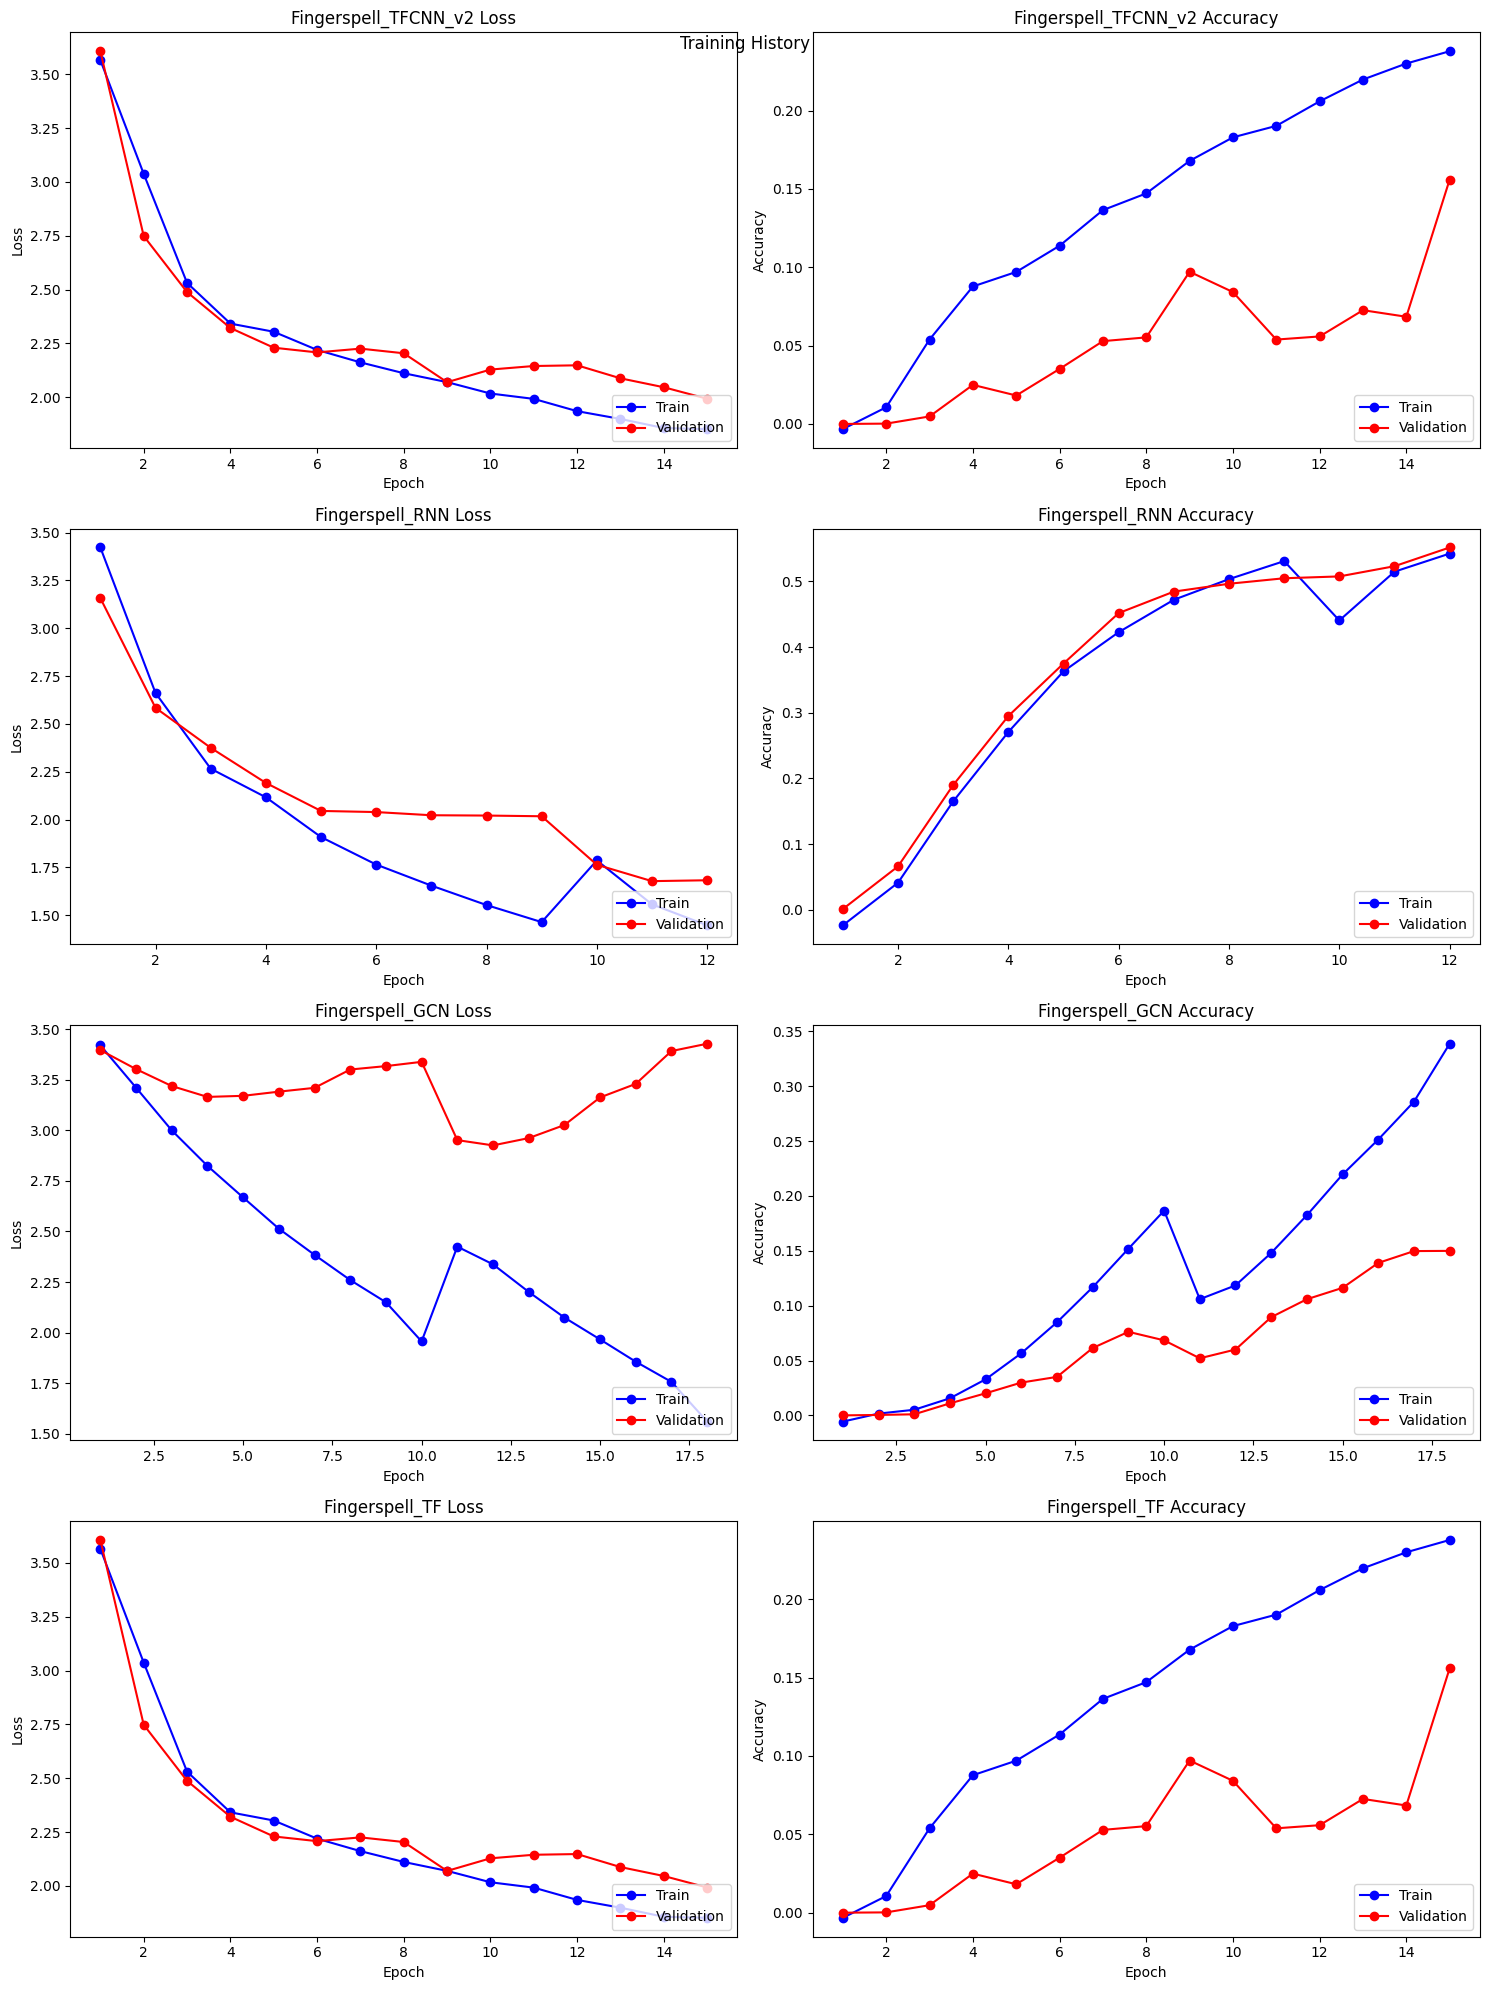

In [ ]:
def plot_history(histories):
    rows=len(histories)
    fig, axes = plt.subplots(nrows=rows, ncols=2, figsize=(15, 5*rows), squeeze=False)

    for i, (model_name, history) in enumerate(histories.items()):
        epochs = range(1, len(history['train_loss'])+1)

        # Loss
        axes[i, 0].plot(epochs, history['train_loss'], 'bo-', label='Train')
        axes[i, 0].plot(epochs, history['val_loss'], 'ro-', label='Validation')
        axes[i, 0].set_title(f'{model_name} Loss')
        axes[i, 0].set_xlabel('Epoch')
        axes[i, 0].set_ylabel('Loss')
        axes[i, 0].legend(loc='lower right')

        # Accuracy
        axes[i, 1].plot(epochs, history['train_acc'], 'bo-', label='Train')
        axes[i, 1].plot(epochs, history['val_acc'], 'ro-', label='Validation')
        axes[i, 1].set_title(f'{model_name} Accuracy')
        axes[i, 1].set_xlabel('Epoch')
        axes[i, 1].set_ylabel('Accuracy')
        axes[i, 1].legend(loc='lower right')

    fig.tight_layout()
    fig.suptitle(f"Training History")
    plt.show()

plot_history(histories)

In [ ]:
decoded, refs = get_ctc_predictions(model_dual_tf, test_loader, DEVICE, blank_idx=BLANK_SYMBOL_IDX)

Running inference: 100%|██████████| 109/109 [03:53<00:00,  2.14s/it]


RNN Results:

Letter accuracy (micro): 0.5044
Letter accuracy (macro): 0.5414
Sequence accuracy (exact match): 0.2016


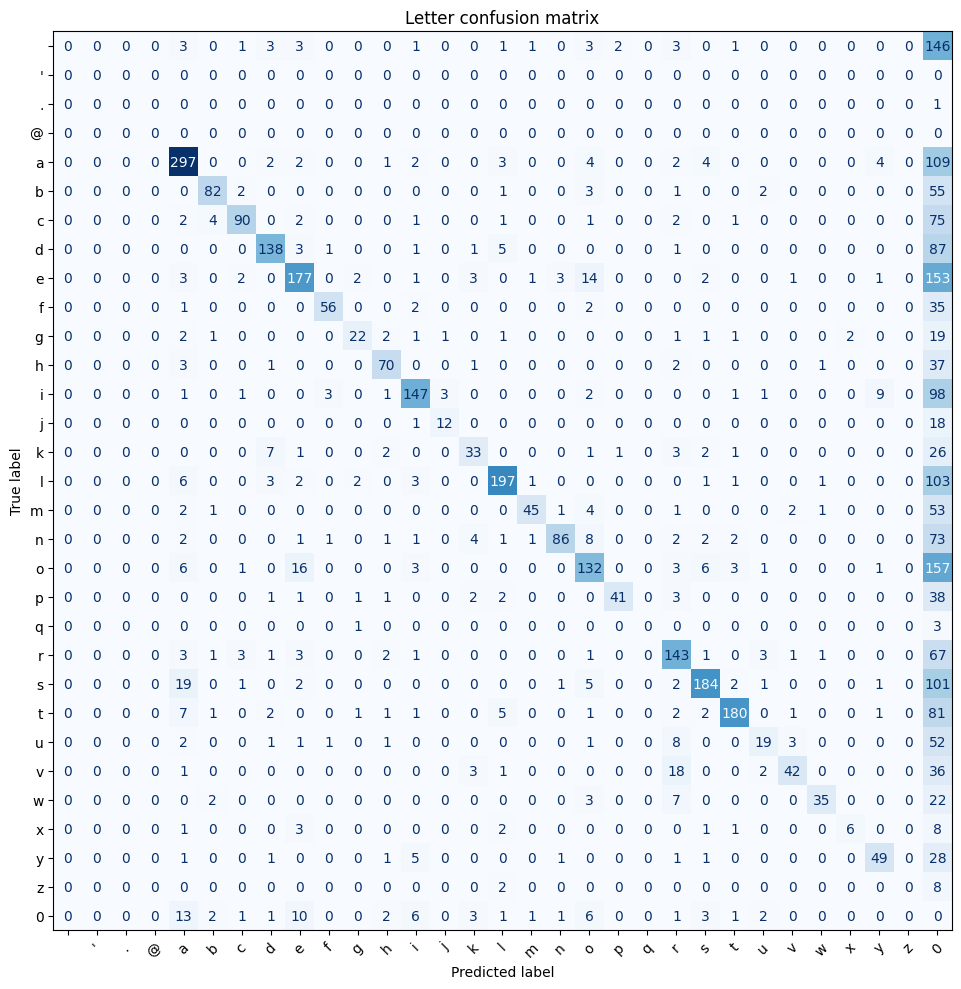

In [ ]:
accumulator = print_ctc_metrics(decoded, refs, vocab=char_vocab)
idx_to_letter = {v: k for k, v in char_vocab.items()}
sdi_breakdown(accumulator)
plot_letter_confusion_matrix(accumulator, idx_to_letter, max_labels=len(char_vocab))

GCN Results:

Letter accuracy (micro): 0.1335
Letter accuracy (macro): 0.1331
Sequence accuracy (exact match): 0.0035


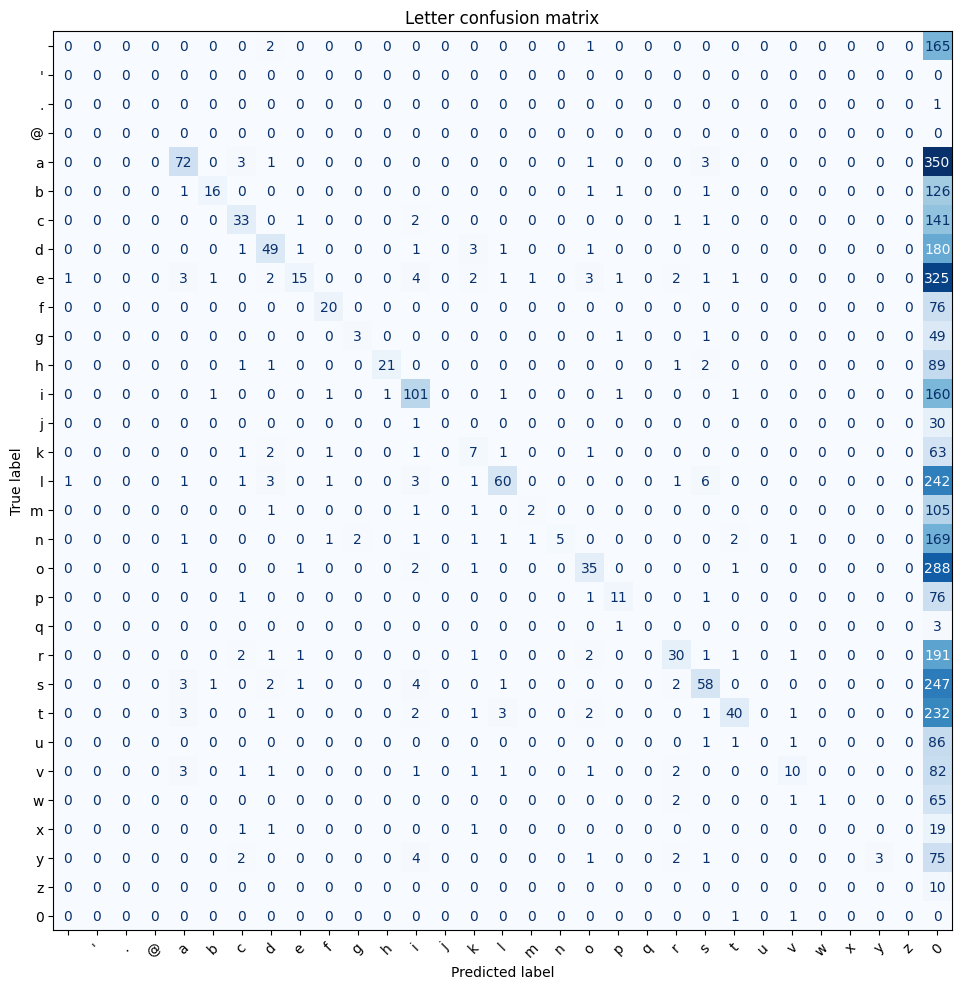

In [ ]:
accumulator = print_ctc_metrics(decoded, refs, vocab=char_vocab)
idx_to_letter = {v: k for k, v in char_vocab.items()}
sdi_breakdown(accumulator)
plot_letter_confusion_matrix(accumulator, idx_to_letter, max_labels=len(char_vocab))

TF Results:

Letter accuracy (micro): 0.1412
Letter accuracy (macro): 0.1796
Sequence accuracy (exact match): 0.0219


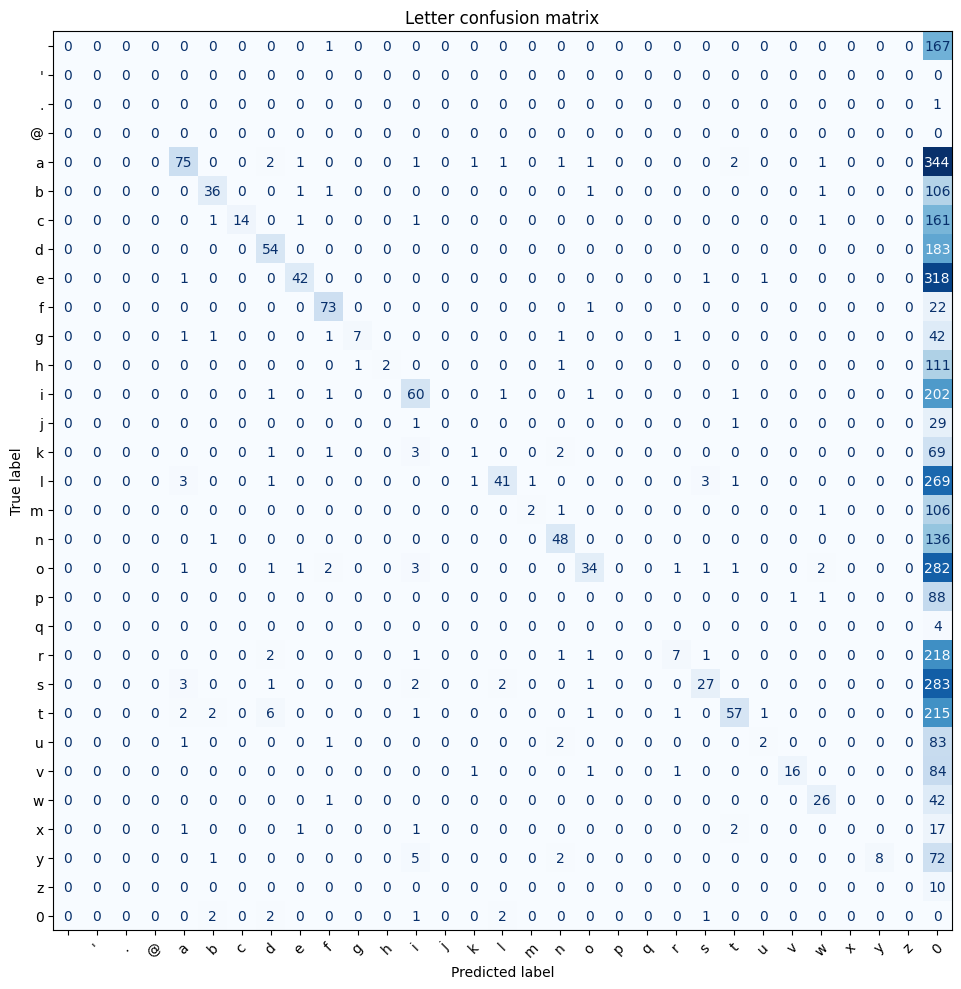

In [ ]:
accumulator = print_ctc_metrics(decoded, refs, vocab=char_vocab)
idx_to_letter = {v: k for k, v in char_vocab.items()}
sdi_breakdown(accumulator)
plot_letter_confusion_matrix(accumulator, idx_to_letter, max_labels=len(char_vocab))